# Project implementation — Interpretable Carbon-Aware Electricity Pricing

MIT 15.095 · Clement Docteur & Panle Chen

This notebook walks through the **actual implementation** of the end-to-end ML pipeline: data preprocessing, carbon-intensity
forecasting, demand-response estimation, tariff optimisation, Optimal Policy Trees, budget-aware trees and household
affordability constraints. It does not re-implement anything: every code listing is pulled **directly from the project's
`.py` files** with `inspect.getsource`, and every computation calls those same functions.

### Two execution modes

| Mode | What runs | Time | Writes |
|---|---|---|---|
| **Review** (default) | Shows the implementation; runs preprocessing replays and *policy evaluation* (simulator + feasibility rules) on **saved** models (coefficients, trees, IAI fits); **no model is trained**. Every result is checked against the saved outputs. | ≈ 1 min | nothing (verified by a hash check at the end) |
| **Full** | 1) rebuilds the household matrix from the raw 8.5 GB csv into a temporary folder and checks it equals the one in use; 2) runs the whole pipeline `run_mvp.py --reproduce` (every stage, incl. IAI); 3) in each section, **trains the models in the notebook** with the project functions (forecasters, demand model, menu, exact and IAI trees, budget-aware and bill-penalised trees) and asserts they reproduce the pipeline's outputs. | ≈ 15–20 min | regenerates `results/` in place (deterministic; the notebook reports whether any file changed); IAI fits go to temporary folders |

Select the mode in the first code cell, or set the environment variable `PROJECT_NOTEBOOK_MODE=full`.

### Cell types (look for the tag in the first line of each code cell)

| Tag | Meaning |
|---|---|
| `# [SOURCE]` | displays the real implementation from the `.py` files (no computation) |
| `# [PREPROCESS]` | runs project preprocessing / feature code on the data (deterministic, in memory, no fitting) |
| `# [TRAIN — full mode only]` | fits models / searches trees with the project code; in review mode it loads the saved fitted artefact instead and says so |
| `# [EVALUATE]` | evaluates a fitted policy (simulator + feasibility rule) — no fitting |
| `# [SAVED RESULT]` | displays saved tables / figures produced by the pipeline |

### Provenance

🟦 **Clement — original, reproduced** (data build, forecast, demand model, menu, exact tree, feasibility rule,
budget-aware tree) · 🟩 **New (MVP)** (leak-free features, average-CI metric, IAI trees, pacing rule, bill caps) ·
🟨 **Retrospective / hindsight** (not deployable).

All emission and bill effects are **model-based counterfactual estimates**. Primary metric: realised **average** carbon
intensity; reduction (%) = 100 × (E_TOU − E_policy) / E_TOU.

## 0. Setup and execution mode

In [1]:
# [SETUP] choose the mode here ("review" or "full"), or set PROJECT_NOTEBOOK_MODE
import os
MODE = os.environ.get("PROJECT_NOTEBOOK_MODE", "review").strip().lower()
assert MODE in ("review", "full"), MODE
FULL = MODE == "full"
print(f"MODE = {MODE!r}:", "training + full pipeline will run" if FULL else "no training; saved models/results are loaded")

MODE = 'review': no training; saved models/results are loaded


In [2]:
# [SETUP] paths, environment, helpers
%matplotlib inline
import hashlib, importlib.util, inspect, json, shutil, subprocess, sys, tempfile, time
from pathlib import Path

ROOT = (Path(os.environ["PROJECT_ROOT"]) if "PROJECT_ROOT" in os.environ     # optional override (e.g. a notebook copy elsewhere)
        else next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_mvp.py").exists()))
PIPE, REPRO, RES = ROOT / "carbon_tariff_pipeline", ROOT / "CVAE_reproduction", ROOT / "results"
MVP = RES / "mvp" / "outputs"
os.environ.setdefault("CARBON_RAW_DIR", str(ROOT.parent))     # raw data folder (read only)
os.environ["CARBON_OUT"] = str(MVP)                            # the MVP outputs (what run_mvp.py writes)
os.environ["CARBON_FIG"] = str(RES / "figures")
for p in (PIPE, REPRO):                                        # both lib/ folders are namespace packages
    sys.path.insert(0, str(p))

import numpy as np, pandas as pd
from IPython.display import Code, Image, Markdown, display
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)

def show(obj, note=""):
    # display the exact source of a function/class from the project files
    src, line = inspect.getsourcelines(obj)
    path = Path(inspect.getsourcefile(obj)).resolve().relative_to(ROOT)
    display(Markdown(f"**Source:** `{path}` line {line}" + (f" — {note}" if note else "")))
    display(Code("".join(src), language="python"))

def show_file(path, language="python", start=None, end=None):
    lines = (ROOT / path).read_text(encoding="utf-8").splitlines()
    i = next(k for k, l in enumerate(lines) if start in l) if start else 0
    j = next(k for k, l in enumerate(lines[i + 1:], i + 1) if end in l) if end else len(lines)
    display(Markdown(f"**Source:** `{path}` lines {i + 1}–{j}"))
    display(Code("\n".join(lines[i:j]), language=language))

def load_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def check(name, got, want, tol=1e-9):
    # compare a live computation with the saved pipeline output and stop on any mismatch
    ok = (abs(got - want) <= tol) if isinstance(want, float) else (got == want)
    detail = f"got {got:.6g} | saved {want:.6g}" if isinstance(want, float) else ("identical" if ok else f"got {got} | saved {want}")
    print(f"[{'MATCH' if ok else 'MISMATCH'}] {name}: {detail}")
    assert ok, name

def tree_hashes():
    # hashes of every saved result + Clement's committed outputs + this repo's notebooks (to prove review mode writes nothing)
    files = [p for d in (RES, PIPE / "outputs", PIPE / "figures") for p in d.rglob("*")
             if p.is_file() and "logs" not in p.parts and not p.name.startswith(".")
             and not p.name.endswith(("_time.csv", "julia.log"))]                    # IAI timing logs vary run to run
    files += [ROOT / "project_walkthrough.ipynb", REPRO / "data" / "lcl2013_build_stats.json", REPRO / "data" / "lcl2013_fill_stats.json"]
    return {str(p.relative_to(ROOT)): hashlib.sha1(p.read_bytes()).hexdigest() for p in files if p.exists()}

T0, HASH0 = time.time(), tree_hashes()
need = [REPRO / "data" / "lcl2013_kwh_filled.npy", MVP / "step3_results_average_mvp.json", MVP / "iai_opt_results_average_mvp.json",
        RES / "pacing" / "pacing_results.json", RES / "affordability" / "affordability_results.json"]
missing = [str(p.relative_to(ROOT)) for p in need if not p.exists()]
if missing and not FULL:
    raise SystemExit(f"missing {missing}: run `.venv/bin/python run_mvp.py --reproduce` once, or use MODE='full'")
JULIA = shutil.which("julia") is not None
print(f"{ROOT.name} | python {sys.version.split()[0]} | {len(HASH0)} files hashed | Julia/IAI available: {JULIA}")

dynamic_pricing_to_reduce_co2 | python 3.12.14 | 2103 files hashed | Julia/IAI available: True


### 0.1 Full mode only: rebuild the data and run the complete pipeline

In **full** mode this cell (i) rebuilds the 2013 household matrix from the raw csv with Clement's
`CVAE_reproduction/scripts/01_build_lcl2013.py` into a *temporary* folder and checks it is identical to the matrix the
pipeline uses (so no cached data is silently trusted, and no tracked file is touched), then (ii) runs
`run_mvp.py --reproduce` — every stage: forecast, demand model, policies, IAI trees, outputs, pacing, affordability,
summary and the reproduction of Clement's Steps 2–3 — and lists which outputs were regenerated. In review mode it does
nothing.

In [3]:
# [TRAIN — full mode only] data rebuild + complete pipeline
if FULL:
    t_start = time.time()
    with tempfile.TemporaryDirectory(prefix="lcl_rebuild_") as tmp:
        r = subprocess.run([sys.executable, "-P", "scripts/01_build_lcl2013.py", "--threads", "8", "--data-dir", tmp, "--work", tmp],
                           cwd=REPRO, capture_output=True, text=True)
        print(r.stdout[-1500:]); assert r.returncode == 0, r.stderr[-3000:]
        fresh = np.load(Path(tmp) / "lcl2013_kwh_filled.npy")
        used = np.load(REPRO / "data" / "lcl2013_kwh_filled.npy", mmap_mode="r")
        print("fresh rebuild identical to the matrix in use:", np.array_equal(fresh, used)); assert np.array_equal(fresh, used)
        del fresh, used
    p = subprocess.Popen([sys.executable, "run_mvp.py", "--reproduce"], cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    assert p.wait() == 0, "run_mvp.py failed - see results/logs/"
    regenerated = [f for f in tree_hashes() if (ROOT / f).stat().st_mtime >= t_start]
    changed = [f for f, h in tree_hashes().items() if HASH0.get(f) != h]
    print(f"\n{len(regenerated)} output files regenerated by the pipeline; {len(changed)} differ from before the run: {changed[:10]}")
else:
    print("[REVIEW] pipeline not run; using the saved outputs in results/")

[REVIEW] pipeline not run; using the saved outputs in results/


In [4]:
# [SETUP] load the project modules (one shared chain: 11_bill_constraint -> 10_pacing -> 07_iai_opt -> 03_policy)
def load_script(name, argv=()):
    sys.argv = [name, *argv]
    spec = importlib.util.spec_from_file_location(name.replace(".py", ""), PIPE / "scripts" / name)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    return mod

M11 = load_script("11_bill_constraint.py")   # loads 10 -> 07 -> 03 with the MVP settings (average CI, lagged temperature)
M10, M7, S3 = M11.M10, M11.M7, M11.S3
M1 = load_script("01_ci_forecast.py")
for _m in (M11, M10, M7, S3, M1):                 # register the file-loaded scripts so inspect can show class sources
    sys.modules[_m.__name__] = _m
from lib import common as C, demand as DM, policy as PO, lcl_data as L
print("Step 3 settings:", S3.METRIC, "| temperature feature:", S3.TEMPERATURE, "| outputs:", Path(C.OUT).relative_to(ROOT))

Step 3 settings: average | temperature feature: lagged | outputs: results/mvp/outputs


## 1. Data loading & preprocessing 🟦

**Raw data** (read only, from `$CARBON_RAW_DIR`): LCL smart meters (`CC_LCL-FullData.csv`, 8.5 GB, kWh per half-hour,
GMT), NESO generation mix and carbon intensity (`df_fuel_ckan.csv`, UTC), ERA5 temperature (`temp UK 2013-14.csv`,
reanalysis), the 2013 tariff schedule.

**Build** (`CVAE_reproduction/scripts/01_build_lcl2013.py`, Clement): one DuckDB scan of the csv → typed parquet → 2013
on-grid rows, duplicates averaged → dense matrix *(households × 17,520 half-hours)* → selection (all TOU households with
> 95 % valid half-hours + an equal seeded sample of flat-tariff "Std" households) → gap filling.

Slot convention: slot *h* of date *d* = the half-hour **ending** at *d* + 30·*h* min GMT (slot 0 = 23:30–24:00 of the
previous day); NESO rows are start-labelled, so CI of slot *h* is the NESO row at *d* + 30·(*h*−1) min.

In [5]:
# [SOURCE] the streaming csv -> parquet scan and household selection
show(L.csv_to_parquet)
show(L.select_households)

**Source:** `CVAE_reproduction/lib/lcl_data.py` line 128

def csv_to_parquet(csv_path=RAW_CSV, out_parquet=None, threads=4, memory_limit="8GB") -> Path:
    """ONE streaming scan of the raw csv -> typed parquet (all years, all rows).

    Columns: LCLid, grp (stdorToU as written), ts (TIMESTAMP parsed from the first 19
    characters, NULL if unparseable), frac_ok (DateTime is 27 chars and ends '.0000000'),
    is_null_str (value == 'Null'), kwh (DOUBLE, NULL if not numeric)."""
    out = Path(out_parquet) if out_parquet else work_dir() / "lcl_full.parquet"
    tmp = out.with_suffix(".tmp.parquet")
    con = duckdb_connect(threads, memory_limit)
    con.execute(f"""COPY (
        SELECT LCLid, stdorToU AS grp,
               try_strptime(substr(DateTime, 1, 19), '%Y-%m-%d %H:%M:%S') AS ts,
               (length(DateTime) = 27 AND substr(DateTime, 20) = '.0000000') AS frac_ok,
               (trim(kwh) = 'Null') AS is_null_str,
               TRY_CAST(trim(kwh) AS DOUBLE) AS kwh
        FROM {csv_source(csv_path)}
    ) TO '{_sql_path(tmp)}' (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 1000000)""")
    con.close()
    os.replace(tmp, out)
    return out

**Source:** `CVAE_reproduction/lib/lcl_data.py` line 451

def select_households(hh: pd.DataFrame, threshold: float = 0.95, seed: int = 0) -> pd.DataFrame:
    """All ToU households with completeness > threshold, plus a random sample (numpy
    default_rng(seed), without replacement, from the LCLid-sorted list) of as many Std
    households with completeness > threshold.  ToU rows first, each block sorted by LCLid."""
    tou = hh[(hh["group"] == "ToU") & (hh["completeness"] > threshold)].sort_values("LCLid")
    std = hh[(hh["group"] == "Std") & (hh["completeness"] > threshold)].sort_values("LCLid")
    rng = np.random.default_rng(seed)
    if len(std) < len(tou):           # only possible on small test extracts
        print(f"WARNING: Std pool ({len(std)}) smaller than ToU set ({len(tou)}); taking all Std")
    draw = rng.choice(len(std), size=min(len(tou), len(std)), replace=False)
    order = np.argsort(draw)
    pick = draw[order]                                   # sorted positions in the LCLid-sorted pool
    std_sel = std.iloc[pick].copy()
    std_sel["std_draw_order"] = order.astype(np.int32)   # i-th household drawn (exchangeable)
    tou = tou.copy()
    tou["std_draw_order"] = np.int32(-1)
    sel = pd.concat([tou, std_sel], ignore_index=True)
    sel = sel[["LCLid", "group", "completeness", "row", "std_draw_order"]].rename(columns={"row": "row_in_dense"})
    sel.insert(2, "row_in_filled", np.arange(len(sel), dtype=np.int32))
    return sel

In [6]:
# [PREPROCESS] peek at the raw csv (first rows only) and replay the household selection on the saved household table
import duckdb
display(duckdb.sql(f"SELECT * FROM {L.csv_source(L.RAW_CSV)} LIMIT 5").df())
hh_table = C.read_parquet(REPRO / "data" / "lcl2013_households.parquet")
sel_live = L.select_households(hh_table, threshold=0.95, seed=0)
sel_saved = C.read_parquet(REPRO / "data" / "selection.parquet")
print(hh_table.groupby("group").size().rename("households with 2013 data").to_string())
check("selected households (LCLid, group, order) identical to the saved selection",
      bool((sel_live[["LCLid", "group"]].to_numpy() == sel_saved[["LCLid", "group"]].to_numpy()).all()), True)
print(sel_live.group.value_counts().to_string())

,LCLid,stdorToU,DateTime,kwh
0,MAC000002,Std,2012-10-12 00:30:00.0000000,0
1,MAC000002,Std,2012-10-12 01:00:00.0000000,0
2,MAC000002,Std,2012-10-12 01:30:00.0000000,0
3,MAC000002,Std,2012-10-12 02:00:00.0000000,0
4,MAC000002,Std,2012-10-12 02:30:00.0000000,0


group
Std    4411
ToU    1117
[MATCH] selected households (LCLid, group, order) identical to the saved selection: identical
group
ToU    1032
Std    1032


In [7]:
# [SOURCE] gap filling (the authors' rule, reverse-engineered by Clement)
show(L.fill_gaps)

**Source:** `CVAE_reproduction/lib/lcl_data.py` line 363

def fill_gaps(X, short_max: int = AUTHORS_SHORT_MAX, long_rule: str = AUTHORS_LONG_RULE, chunk: int = 400):
    """Paper Sec. III gap filling on the LCL grid (n, 17520).

    * gaps (maximal runs of missing slots) of length <= ``short_max`` that have an
      observed value on both sides: linear interpolation in time between those two values;
    * every other missing slot (long gaps, or gaps touching the start/end of the year), at
      day d and half-hour h, from the nearest preceding day p and nearest following day q
      that have an OBSERVED value at half-hour h:
        - ``long_rule='linear_days'``: linear interpolation across days,
          x[p,h] + (x[q,h] - x[p,h]) * (d - p) / (q - p)   (= their mean when p, q = d -+ 1);
        - ``long_rule='mean_nearest'``: the mean of x[p,h] and x[q,h];
      only one side when the other does not exist (year edges).
    Defaults (short_max=1, 'linear_days') = the authors' rule, reverse-engineered from their
    all-ToU aggregate (scripts/02_lcl_checks.py, outputs/data_checks.json 'gap_fill_rule').
    The orchestration spec's variant is short_max=4, 'mean_nearest'.
    Returns (filled float32, stats dict)."""
    assert long_rule in ("linear_days", "mean_nearest"), long_rule
    X = np.asarray(X)
    n, T = X.shape
    assert T == N_SLOTS
    out = np.empty((n, T), dtype=np.float32)
    n_short = n_long = n_left = 0
    n_long_one_side = 0
    run_hist: dict[int, int] = {}
    idx = np.arange(T)
    days = np.arange(N_DAYS)
    for a in range(0, n, chunk):
        x = X[a:a + chunk].astype(np.float64)
        k = x.shape[0]
        valid = ~np.isnan(x)
        miss = ~valid
        prev = np.maximum.accumulate(np.where(valid, idx, -1), axis=1)
        nxt = np.minimum.accumulate(np.where(valid, idx, T)[:, ::-1], axis=1)[:, ::-1]
        gap_len = nxt - prev - 1
        # run-length histogram (each run counted once, at its first slot)
        first = miss & (prev == idx - 1)
        for L, c in zip(*np.unique(np.minimum(gap_len[first], 49), return_counts=True)):
            run_hist[int(L)] = run_hist.get(int(L), 0) + int(c)
        short = miss & (prev >= 0) & (nxt < T) & (gap_len <= short_max)
        y = x.copy()
        rr, cc = np.nonzero(short)
        p = prev[rr, cc]
        q = nxt[rr, cc]
        w = (cc - p) / (q - p)
        y[rr, cc] = x[rr, p] * (1.0 - w) + x[rr, q] * w
        n_short += len(rr)
        longm = miss & ~short
        if longm.any():
            xd = x.reshape(k, N_DAYS, H)
            vd = valid.reshape(k, N_DAYS, H)
            pdy = np.maximum.accumulate(np.where(vd, days[None, :, None], -1), axis=1)
            ndy = np.minimum.accumulate(np.where(vd, days[None, :, None], N_DAYS)[:, ::-1, :], axis=1)[:, ::-1, :]
            li, ld, lh = np.nonzero(longm.reshape(k, N_DAYS, H))
            p_d = pdy[li, ld, lh]
            n_d = ndy[li, ld, lh]
            vp = np.where(p_d >= 0, xd[li, np.clip(p_d, 0, N_DAYS - 1), lh], np.nan)
            vn = np.where(n_d < N_DAYS, xd[li, np.clip(n_d, 0, N_DAYS - 1), lh], np.nan)
            both = np.vstack([vp, vn])
            cnt_ = (~np.isnan(both)).sum(axis=0)
            fill = np.where(cnt_ > 0, np.nansum(both, axis=0) / np.maximum(cnt_, 1), np.nan)
            if long_rule == "linear_days":
                two = cnt_ == 2
                wd = (ld[two] - p_d[two]) / (n_d[two] - p_d[two])
                fill[two] = vp[two] + (vn[two] - vp[two]) * wd
            y.reshape(k, N_DAYS, H)[li, ld, lh] = fill
            n_long += len(li)
            n_long_one_side += int((cnt_ == 1).sum())
            n_left += int(np.isnan(fill).sum())
        out[a:a + k] = y.astype(np.float32)
    stats = {"short_max_slots": short_max, "long_rule": long_rule, "filled_short_linear": int(n_short),
             "filled_long_sameslot_days": int(n_long), "filled_long_one_side_only": int(n_long_one_side),
             "left_missing": int(n_left),
             "gap_runs_by_length_(49=>=49)": {str(k_): v for k_, v in sorted(run_h

In [8]:
# [PREPROCESS] replay gap filling on the 40 selected households with the most missing half-hours
raw = np.load(REPRO / "data" / "lcl2013_kwh.npy", mmap_mode="r") if (REPRO / "data" / "lcl2013_kwh.npy").exists() else None
filled_all = np.load(REPRO / "data" / "lcl2013_kwh_filled.npy", mmap_mode="r")
if raw is not None:
    rows = sel_saved.row_in_dense.to_numpy()
    n_missing = np.isnan(raw[rows]).sum(1)
    pick = np.argsort(-n_missing)[:40]
    X_sub = np.asarray(raw[rows[pick]])
    F_sub, stats = L.fill_gaps(X_sub)
    print(f"missing half-hours in these households: {int(np.isnan(X_sub).sum()):,}; filled: short {stats['filled_short_linear']}, long {stats['filled_long_sameslot_days']}")
    check("gap-filled rows identical to the saved filled matrix", bool(np.array_equal(F_sub, np.asarray(filled_all[sel_saved.row_in_filled.to_numpy()[pick]]))), True)
else:
    print("raw dense matrix (gitignored) not present; run the data stage to replay gap filling")

missing half-hours in these households: 12,123; filled: short 107, long 12016
[MATCH] gap-filled rows identical to the saved filled matrix: identical


**Household aggregation.** TOU households are grouped into 4 behavioural clusters (Clement's NMF + k-medoids
reproduction of Brégère & Bessa; sizes 285/299/299/149). The demand model works on **cluster-mean** consumption, and the
flat-tariff households' mean is the control series.

**Source:** `carbon_tariff_pipeline/lib/common.py` line 164

def load_households(std=True):
    """Household kWh (n, 365, 48) float32 for the 1,032 ToU households (+ cluster labels) and, if std, the 1,032
    flat-tariff (Std) ones.

    Clusters = Track B of the reproduction (our NMF + k-medoids run (a), relabelled to the paper's 0-3 with the
    Hungarian map {nmf 0->2, 1->0, 2->1, 3->3}; sizes 285/299/299/149). Cluster means reproduce
    power_consump_ours.parquet to < 4e-7 kWh.
    """
    K = np.load(REPRO / "data" / "lcl2013_kwh_filled.npy", mmap_mode="r")
    cl = read_parquet(REPRO / "data" / "clusters_run_a.parquet")
    tou = cl[cl.group == "ToU"].sort_values("row_in_filled")
    out = dict(cluster=tou["nmf"].map({0: 2, 1: 0, 2: 1, 3: 3}).to_numpy(int),
               Y_tou=np.asarray(K[tou.row_in_filled.to_numpy()]).reshape(-1, 365, H))
    if std:
        rows = cl[cl.group == "Std"].sort_values("row_in_filled").row_in_filled.to_numpy()
        out["Y_std"] = np.asarray(K[rows]).reshape(-1, 365, H)
    return out

**Source:** `carbon_tariff_pipeline/lib/common.py` line 183

def cluster_aggregates(hh):
    """sizes (4,), household weights w (4,), cluster-mean kWh Yc (4, 365, 48) and the household mean y_all (365, 48)."""
    cl = hh["cluster"]
    sizes = np.bincount(cl)
    w = sizes / sizes.sum()
    Yc = np.stack([hh["Y_tou"][cl == c].mean(0) for c in range(4)]).astype(float)
    return sizes, w, Yc, np.einsum("c,cdh->dh", w, Yc)

cluster sizes: [285, 299, 299, 149] | household weights: [0.276, 0.29, 0.29, 0.144]


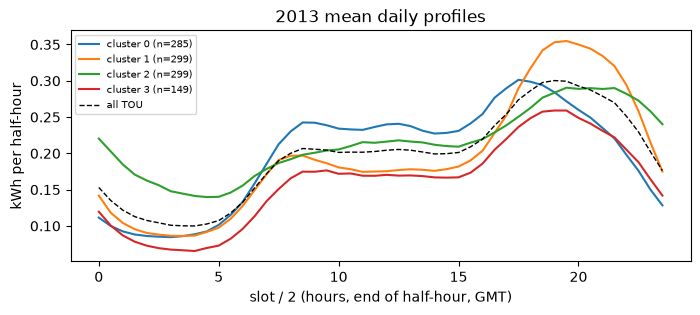

In [9]:
# [SOURCE] + [PREPROCESS] household loading and cluster aggregation
show(C.load_households); show(C.cluster_aggregates)
sizes, W, YC, YALL = S3.SIZES, S3.W, S3.YC, S3.YALL
print("cluster sizes:", sizes.tolist(), "| household weights:", W.round(3).tolist())
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3))
hrs = np.arange(48) / 2
for c in range(4):
    ax.plot(hrs, YC[c].mean(0), label=f"cluster {c} (n={sizes[c]})")
ax.plot(hrs, S3.hh["Y_tou"].mean((0, 1)), "k--", lw=1, label="all TOU")
ax.set_xlabel("slot / 2 (hours, end of half-hour, GMT)"); ax.set_ylabel("kWh per half-hour"); ax.legend(fontsize=7); ax.set_title("2013 mean daily profiles")
plt.show()

**Chronological splits.** Main analysis: train Jan–Aug (243 days), validation Sep–Oct (61), test Nov–Dec (61).
Rolling evaluation: four 2-month test windows; each is validated on the 2 preceding months and trained on all earlier days
(`03_policy.Fold`). Model selection, menus, price targets and bill references use only training/validation days.

In [10]:
# [SOURCE] + [PREPROCESS] the rolling folds
show(S3.Fold)
display(pd.DataFrame([{"test window": f.label, "train days": len(f.train), "validation days": len(f.val), "test days": len(f.test),
                       "price target = historical TOU avg over train+val (p/kWh)": S3.PRICE_H[f.trainval].mean()}
                      for f in (S3.Fold(m) for m in (5, 7, 9, 11))]))

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 166

class Fold:
    """Chronological split of 2013: training days, a 2-month validation window, then a 2-month test window
    starting in month `test_month`. Holds the test-day households and the historical (observed) reference."""

    def __init__(self, test_month):
        m = DATES_2013.month
        self.test_month = test_month
        self.train = np.where(m < test_month - 2)[0]
        self.val = np.where((m >= test_month - 2) & (m < test_month))[0]
        self.test = np.where((m >= test_month) & (m < test_month + 2))[0]
        self.trainval = np.concatenate([self.train, self.val])
        self.label = f"{calendar.month_abbr[test_month]}-{calendar.month_abbr[test_month + 1]}"
        self.Y = hh["Y_tou"][:, self.test].astype(float)    # households on the test days, for bills
        self.ref = evaluate(self, None, LOW_H[self.test], HIGH_H[self.test])
        self.footprint = emissions(self, self.ref["y"], CI)  # historical footprint at average intensity: % denominator

,test window,train days,validation days,test days,price target = historical TOU avg over train+val (p/kWh)
0,May-Jun,59,61,61,13.630
1,Jul-Aug,120,61,62,14.092
2,Sep-Oct,181,62,61,13.630
3,Nov-Dec,243,61,61,13.608


## 2. Carbon-intensity forecasting 🟦

**Decision timing.** Tariffs for day *d* are announced at **12:00 GMT on d−1**, so the forecast may only use NESO data up to
the half-hour ending 12:00 on d−1 (horizon 12–36 h).

**Target.** Each slot's CI minus the **anchor** (mean CI of the last 24 h known); models predict the deviation and the
anchor is added back:  $\widehat{CI}_{d,h} = \text{anchor}_d + f(x_{d,h})$.

**Features** (`build_frame`): anchor, last value, 3-h trend, lagged day means, generation-mix shares (coal, gas, wind,
nuclear, imports; last value and 24-h mean), seasonality, weekday, holidays, slot-specific lags.

**Models** (`LinearModel`, `TreeModel`, `make_model`): Ridge and Lasso on standardised numerics + slot/weekday one-hots +
slot × lag interactions; Random Forest and XGBoost on the raw table. Hyper-parameters chosen by **validation MAE**
(train ≤ 2013-08-30, validate Sep–Oct); then **monthly expanding refits** (model for month *m* trained on all days ≤ 1st of
*m* − 2 days) give an out-of-sample forecast for every 2013 day. Test = Nov–Dec.

In [11]:
# [SOURCE] feature construction and models
show(M1.build_frame); show(M1.LinearModel); show(M1.TreeModel); show(M1.make_model)

**Source:** `carbon_tariff_pipeline/scripts/01_ci_forecast.py` line 41

def build_frame(neso: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    ci, gen = neso.CARBON_INTENSITY.astype(float), neso.GENERATION.astype(float)
    share = lambda cols: neso[cols].sum(axis=1) / gen
    mix = {"coal": share(["COAL"]), "gas": share(["GAS"]), "wind": share(["WIND", "WIND_EMB"]),
           "nuclear": share(["NUCLEAR"]), "imports": share(["IMPORTS"])}
    allday = pd.date_range(DAYS[0] - pd.Timedelta(days=8), DAYS[-1], freq="D")
    CI = pd.DataFrame(day_matrix(ci, allday), index=allday)
    GEN = pd.DataFrame(day_matrix(gen, allday), index=allday)
    lagged = lambda frame, k: frame.loc[DAYS - pd.Timedelta(days=k)]
    n = len(DAYS)
    cut = DAYS - pd.Timedelta(days=1) + pd.Timedelta(hours=11, minutes=30)          # last known NESO row (start label)
    last24 = (cut.values[:, None] - np.arange(H)[None, :] * HH).ravel()             # 48 rows up to the cut
    ci24 = ci.reindex(last24).to_numpy().reshape(n, H)
    day = pd.DataFrame(index=DAYS)
    day["anchor"] = ci24.mean(1)
    day["last"] = ci24[:, 0]
    day["trend3h"] = ci24[:, 0] - ci24[:, 6]
    day["daymean_2"] = lagged(CI, 2).mean(axis=1).to_numpy()
    day["daymean_7"] = lagged(CI, 7).mean(axis=1).to_numpy()
    for k, s in mix.items():
        day[f"{k}_last"] = s.reindex(cut).to_numpy()
        day[f"{k}_24h"] = s.reindex(last24).to_numpy().reshape(n, H).mean(1)
    day["gen_last"] = gen.reindex(cut).to_numpy() / 1000
    day["gen_24h"] = gen.reindex(last24).to_numpy().reshape(n, H).mean(1) / 1000
    doy = DAYS.dayofyear.to_numpy()
    day["doy_sin"], day["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    day["dow"] = DAYS.dayofweek
    day["holiday"] = DAYS.isin(BANK_HOLIDAYS).astype(float)

    lag2, lag7 = lagged(CI, 2).to_numpy(), lagged(CI, 7).to_numpy()
    lag_recent = np.where((np.arange(H) <= 24)[None, :], lagged(CI, 1).to_numpy(), lag2)   # slot h of d-1 known by 12:00 if h <= 24
    rows = pd.DataFrame({"date": np.repeat(DAYS.values, H), "slot": np.tile(np.arange(H), n)})
    for c in day.columns:
        rows[c] = np.repeat(day[c].to_numpy(), H)
    A = np.repeat(day["anchor"].to_numpy(), H)
    rows["lag_recent_dev"] = lag_recent.ravel() - A
    rows["lag2_dev"] = lag2.ravel() - A
    rows["lag7_dev"] = lag7.ravel() - A
    rows["gen_lag7"] = lagged(GEN, 7).to_numpy().ravel() / 1000
    for c in ("last", "daymean_2", "daymean_7"):
        rows[c] = rows[c] - A                                # all CI lags as deviations from the anchor
    return rows, day_matrix(ci, DAYS)

**Source:** `carbon_tariff_pipeline/scripts/01_ci_forecast.py` line 92

class LinearModel:
    """Ridge/Lasso on standardised numerics + slot and weekday one-hots + slot x lag interactions."""

    def __init__(self, kind, alpha, extra=()):
        self.kind, self.alpha, self.extra = kind, alpha, list(extra)

    def design(self, df):
        S = np.eye(H)[df.slot.to_numpy()]
        inter = S * df["lag_recent_dev"].to_numpy()[:, None]           # slot-specific persistence
        return df[NUM + self.extra].to_numpy(float), np.hstack([S, np.eye(7)[df.dow.to_numpy()], inter / 50.0])

    def fit(self, df, y):
        num, cat = self.design(df)
        self.sc = StandardScaler().fit(num)
        est = Ridge(alpha=self.alpha) if self.kind == "ridge" else Lasso(alpha=self.alpha, max_iter=5000)
        self.m = est.fit(np.hstack([self.sc.transform(num), cat]), y)
        return self

    def predict(self, df):
        num, cat = self.design(df)
        return self.m.predict(np.hstack([self.sc.transform(num), cat]))

**Source:** `carbon_tariff_pipeline/scripts/01_ci_forecast.py` line 115

class TreeModel:
    """Random forest or XGBoost on the raw feature table (slot and weekday as integers)."""

    def __init__(self, make_estimator, extra=()):
        self.make, self.extra = make_estimator, list(extra)

    def X(self, df):
        return df[NUM + ["slot", "dow"] + self.extra].to_numpy(float)

    def fit(self, df, y):
        self.m = self.make().fit(self.X(df), y)
        return self

    def predict(self, df, n_trees=None):
        return self.m.predict(self.X(df), **({"iteration_range": (0, n_trees)} if n_trees else {}))

**Source:** `carbon_tariff_pipeline/scripts/01_ci_forecast.py` line 132

def make_model(name, p, extra=()):
    if name in ("ridge", "lasso"):
        return LinearModel(name, p["alpha"], extra)
    if name == "rf":
        return TreeModel(lambda: RandomForestRegressor(n_estimators=200, max_samples=0.5, n_jobs=4, random_state=0, **p), extra)
    return TreeModel(lambda: XGBRegressor(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
                                          n_jobs=4, random_state=0, tree_method="hist", **p), extra)

In [12]:
# [SOURCE] model selection on validation + monthly expanding refits (the training procedure of Step 1)
show(M1.main, "the selection grid, the monthly refits and the metrics")

**Source:** `carbon_tariff_pipeline/scripts/01_ci_forecast.py` line 158 — the selection grid, the monthly refits and the metrics

def main():
    df, Y = build_frame(load_neso())
    temps = load_temps_2013()
    n13 = len(DATES_2013)
    tday = np.full(len(DAYS), np.nan)
    tday[-n13:] = temps.mean(1)
    tday_lag2 = np.roll(tday, 2)
    tday_lag2[-n13:-n13 + 2] = np.nan
    df["temp_slot"] = np.concatenate([np.full((len(DAYS) - n13) * H, np.nan), temps.ravel()])
    df["temp_day"] = np.repeat(tday, H)
    df["temp_day_change"] = np.repeat(tday - tday_lag2, H)
    anchor = df["anchor"].to_numpy().reshape(-1, H)
    ydev = (Y - anchor).ravel()
    dd = df["date"].to_numpy()
    per_day = lambda mask: mask.reshape(-1, H)[:, 0]

    def month_masks(m, start=None):
        """Training rows (days <= 1st of month m - 2 days, optionally from `start`), forecast rows, and 2013 day rows."""
        m1, m2 = pd.Timestamp(2013, m, 1), pd.Timestamp(2013, m, 1) + pd.offsets.MonthBegin(1)
        train = dd <= np.datetime64(m1 - pd.Timedelta(days=2))
        if start:
            train &= dd >= np.datetime64(start)
        return train, (dd >= np.datetime64(m1)) & (dd < np.datetime64(m2)), (DATES_2013 >= m1) & (DATES_2013 < m2)

    tr, va = dd <= np.datetime64("2013-08-30"), (dd >= np.datetime64("2013-09-01")) & (dd <= np.datetime64("2013-10-31"))
    log(f"{len(DAYS)} days x 48 slots; train rows {tr.sum():,}, val rows {va.sum():,}")

    # ---------------- model selection on validation
    grids = {"ridge": [{"alpha": a} for a in (10, 100, 1000, 3000, 10000, 30000, 100000)],
             "lasso": [{"alpha": a} for a in (0.03, 0.1, 0.3, 1.0, 3.0)],
             "rf": [{"max_features": f, "min_samples_leaf": l} for f in (0.33, 0.66) for l in (5, 25, 100)],
             "xgb": [{"max_depth": d, "n_estimators": 1000} for d in (2, 3, 5)]}
    best, best_mae = {}, {}
    yv, av = Y[per_day(va)], anchor[per_day(va)]
    for name, grid in grids.items():
        res = []
        for p in grid:
            m = make_model(name, p).fit(df[tr], ydev[tr])
            for nt in ((100, 200, 500, 1000) if name == "xgb" else (None,)):   # xgb: score each ensemble size
                pr = (m.predict(df[va], n_trees=nt) if nt else m.predict(df[va])).reshape(-1, H) + av
                res.append(({**p, "n_estimators": nt} if nt else p, float(np.abs(pr - yv).mean())))
        best[name], best_mae[name] = min(res, key=lambda t: t[1])
        log(f"{name}: best {best[name]} val MAE {best_mae[name]:.2f}")
    sel = min(best_mae, key=best_mae.get)
    log(f"selected model (lowest validation MAE): {sel}")

    # ---------------- monthly expanding refits over 2013 (out-of-sample forecasts for every 2013 day)
    F = {k: np.full((365, H), np.nan) for k in grids}
    for m in range(1, 13):
        trm, tem, rows13 = month_masks(m)
        for name in grids:
            F[name][rows13] = make_model(name, best[name]).fit(df[trm], ydev[trm]).predict(df[tem]).reshape(-1, H) + anchor[per_day(tem)]
        log(f"refit month {m} done")
    A13, anc13 = Y[-n13:], anchor[-n13:]
    F["persist_latest"] = df["lag_recent_dev"].to_numpy().reshape(-1, H)[-n13:] + anc13
    F["persist_7d"] = df["lag7_dev"].to_numpy().reshape(-1, H)[-n13:] + anc13
    F["flat24h"] = anc13.copy()

    # ---------------- validation + test metrics
    sp = split_of(DATES_2013)
    va13, te13 = sp == "val", sp == "test"
    table = {k: {"test": metrics(F[k][te13], A13[te13]), "val": metrics(F[k][va13], A13[va13])} for k in F}
    for k, v in table.items():
        log(f"{LABELS[k]:36s} test MAE {v['test']['MAE']:.1f} RMSE {v['test']['RMSE']:.1f} rho {v['test']['within_day_spearman']:.2f} "
            f"spread {v['test']['spread_captured_3h']:.2f} | val MAE {v['val']['MAE']:.1f}")

    # ---------------- does weather help? 2013-only training window, best xgb params, with/without temperature
    wx = {}
    for label, extra in (("no weather", ()), ("with ERA5 temperature", TEMP)):
        out = np.full((365, H), np.nan)
        for m in range(3, 13):                                 # Jan-Feb: too little 2013 history
            t

In [13]:
# [PREPROCESS] build the real feature table (2009-2013, 87k rows x 48 slots)
df_ci, Y_ci = M1.build_frame(C.load_neso())
anchor = df_ci["anchor"].to_numpy().reshape(-1, 48)
ydev = (Y_ci - anchor).ravel()
dd = df_ci["date"].to_numpy()
tr = dd <= np.datetime64("2013-08-30"); va = (dd >= np.datetime64("2013-09-01")) & (dd <= np.datetime64("2013-10-31"))
print(f"feature table {df_ci.shape}; train rows {tr.sum():,}, validation rows {va.sum():,}")
display(df_ci.loc[va, ["date", "slot"] + M1.NUM[:8]].head(4))

feature table (87264, 27); train rows 81,360, validation rows 2,928


,date,slot,anchor,last,trend3h,daymean_2,daymean_7,coal_last,coal_24h,gas_last
81408,2013-09-01,0,423.792,-2.792,-9.0,37.958,62.104,0.357,0.359,0.178
81409,2013-09-01,1,423.792,-2.792,-9.0,37.958,62.104,0.357,0.359,0.178
81410,2013-09-01,2,423.792,-2.792,-9.0,37.958,62.104,0.357,0.359,0.178
81411,2013-09-01,3,423.792,-2.792,-9.0,37.958,62.104,0.357,0.359,0.178


In [14]:
# [TRAIN — full mode only] fit the four models at their selected hyper-parameters and score validation MAE;
#                          refit the selected model for Nov and Dec and compare with the saved test forecasts
m1 = load_json(MVP / "step1_metrics.json")
if FULL:
    per_day = lambda mask: mask.reshape(-1, 48)[:, 0]
    yv, av = Y_ci[per_day(va)], anchor[per_day(va)]
    rows_ = []
    for name, p in m1["best_params"].items():
        p = dict(p); nt = p.pop("n_estimators", None)
        mdl = M1.make_model(name, {**p, "n_estimators": 1000} if name == "xgb" else p).fit(df_ci[tr], ydev[tr])
        pred = (mdl.predict(df_ci[va], n_trees=nt) if name == "xgb" else mdl.predict(df_ci[va])).reshape(-1, 48) + av
        rows_.append({"model": m1["labels"][name], "params": m1["best_params"][name], "validation MAE (selection fit)": float(np.abs(pred - yv).mean())})
    display(pd.DataFrame(rows_))
    sel = m1["selected_model"]; saved = np.load(MVP / "ci_forecasts_2013.npz")["selected"]
    for m in (11, 12):
        m1d, m2d = pd.Timestamp(2013, m, 1), pd.Timestamp(2013, m, 1) + pd.offsets.MonthBegin(1)
        trm = dd <= np.datetime64(m1d - pd.Timedelta(days=2)); tem = (dd >= np.datetime64(m1d)) & (dd < np.datetime64(m2d))
        live = M1.make_model(sel, m1["best_params"][sel]).fit(df_ci[trm], ydev[trm]).predict(df_ci[tem]).reshape(-1, 48) + anchor[per_day(tem)]
        rows13 = (C.DATES_2013 >= m1d) & (C.DATES_2013 < m2d)
        check(f"month {m} refit reproduces the saved forecasts (max abs diff)", float(np.abs(live - saved[rows13]).max()), 0.0, tol=1e-6)
else:
    print("[REVIEW] no forecaster trained; selected hyper-parameters (from the saved run):", m1["best_params"])

[REVIEW] no forecaster trained; selected hyper-parameters (from the saved run): {'ridge': {'alpha': 3000}, 'lasso': {'alpha': 0.3}, 'rf': {'max_features': 0.33, 'min_samples_leaf': 25}, 'xgb': {'max_depth': 3, 'n_estimators': 200}}


,val MAE,val RMSE,test MAE,test RMSE
Random forest,24.261,32.141,25.969,34.343
XGBoost,24.003,31.509,27.558,35.459
"Persistence: same slot, latest day",31.561,42.526,28.432,38.582
Flat: mean of last 24 h,31.462,41.151,28.553,38.016
Ridge,25.783,33.203,29.528,37.806
Lasso,25.983,33.461,30.139,38.594
"Persistence: same slot, 7 days ago",37.512,50.482,32.712,43.230


selected on validation MAE: XGBoost


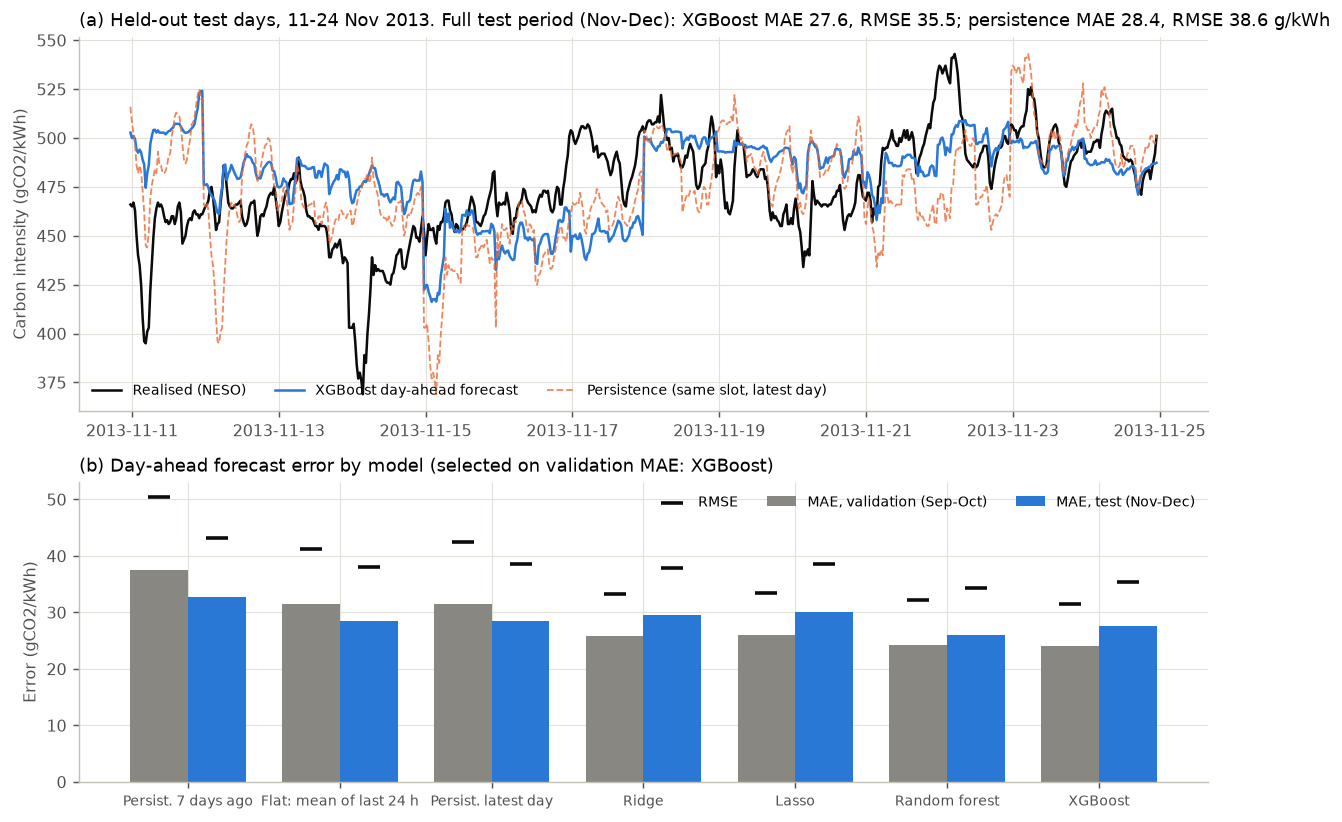

In [15]:
# [SAVED RESULT] validation and test errors of the monthly refits; Figure 1
display(pd.DataFrame({m1["labels"][k]: {f"{s} {e}": v[s][e] for s in ("val", "test") for e in ("MAE", "RMSE")} for k, v in m1["metrics"].items()}).T.sort_values("test MAE"))
print("selected on validation MAE:", m1["labels"][m1["selected_model"]])
display(Image(filename=str(RES / "figures" / "fig1_carbon_forecast.png"), width=900))

## 3. Household demand-response modelling 🟦

For each cluster *c*, the log ratio of TOU to flat-tariff (Std) consumption is regressed on day-type × slot intercepts,
temperature × time-of-day band and **tariff regressors**:

$$\log \frac{\bar y^{TOU}_{c,d,h}}{\bar y^{Std}_{d,h}} = \alpha_{c,\,daytype(d),\,h} + \gamma_{c,\,band(h)}\,\frac{T_{d,h}-10}{10}
+ \underbrace{\sum_k \theta_{c,k}\, R_k(z_d)_h}_{m_c(z_d)_h} + \varepsilon$$

with $R_k$ = in-block High/Low indicators (pooled + time-of-day band deviations, ridge-shrunk) and edge terms: 2 h before
Low (pre-shift dip), the half-hour after Low (rebound), 2 h before High. The Std households are a contemporaneous
**control** (difference-in-differences), so weather, holidays and seasonal swings cancel.

**Counterfactual:** under any whole-day schedule *z*,  $\hat y_{c,d,h}(z) = y^{obs}_{c,d,h}\,\exp\big(m_c(z)_h - m_c(z^{TOU}_d)_h\big)$
(clipped to [¼, 4]). So demand depends on the **entire** schedule — conservation, pre-event dips and rebound.

**Assumptions:** coefficients are observational associations (not causal), identified only for schedule shapes seen in
2013; no fatigue or income effects; the CVAE (not retrained) is only a sensitivity world.

In [16]:
# [SOURCE] tariff regressors and the response model
show(DM.tariff_regressors); show(DM.ResponseModel)

**Source:** `carbon_tariff_pipeline/lib/demand.py` line 55

def tariff_regressors(low, high, timeline=False) -> dict:
    """Tariff regressors for schedules given as (n_days, 48) 0/1 arrays. timeline=True treats the rows as one
    continuous series (blocks and their edges may cross midnight, as in the historical schedule); timeline=False
    treats each day on its own. Returns name -> (n_days, 48) float."""
    low, high = np.asarray(low, bool), np.asarray(high, bool)
    n = low.shape[0]
    if timeline:
        L, Hh = low.reshape(1, -1), high.reshape(1, -1)
        band = np.tile(BAND_OF, n)[None]
        anyH, anyL = np.repeat(high.any(1), H)[None], np.repeat(low.any(1), H)[None]
    else:
        L, Hh, band = low, high, BAND_OF[None]
        anyH, anyL = high.any(1, keepdims=True), low.any(1, keepdims=True)
    ev = L | Hh
    preH = ~Hh & _any_shift(Hh, range(1, 5))            # a High slot within the next 2 h
    postH = ~Hh & _any_shift(Hh, range(-4, 0))          # a High slot within the last 2 h
    preL = ~L & _any_shift(L, range(1, 5))
    postL1 = ~L & _any_shift(L, [-1])
    postL2 = ~L & ~postL1 & _any_shift(L, range(-4, -1))
    r = {"in_High": Hh, "in_Low": L, "pre2h_High": preH, "post2h_High": postH, "pre2h_Low": preL,
         "post30m_Low": postL1, "post2h_Low": postL2}
    for i, b in enumerate(BANDS):
        r[f"in_High|{b}"] = Hh & (band == i)
        r[f"in_Low|{b}"] = L & (band == i)
    r["day_High"] = anyH & ~Hh & ~preH & ~postH & ~ev
    r["day_Low"] = anyL & ~L & ~preL & ~postL1 & ~postL2 & ~ev
    return {k: np.broadcast_to(v, L.shape).reshape(n, H).astype(float) for k, v in r.items()}

**Source:** `carbon_tariff_pipeline/lib/demand.py` line 84

class ResponseModel:
    """Per-cluster log-ratio regression: fit_cluster() on chosen days, then log_effect() for any schedule."""

    def __init__(self, spec="main", ridge_band=30.0, scale=1.0):
        self.spec, self.ridge_band, self.scale = spec, ridge_band, scale
        self.terms = POOLED + BAND_TERMS + SPECS[spec]
        self.p0 = 2 * H + len(BANDS)                       # columns before the tariff terms
        self.theta: dict[int, np.ndarray] = {}
        self.baseline_coef: dict[int, np.ndarray] = {}

    def design(self, low, high, temp, daytype):
        """Design matrix for the historical year: [slot x day-type intercepts | temperature x band | tariff terms]."""
        n = low.shape[0]
        R = tariff_regressors(low, high, timeline=True)
        slot = np.tile(np.arange(H), n)
        icpt = np.zeros((n * H, 2 * H))
        icpt[np.arange(n * H), slot + H * np.repeat(daytype, H)] = 1.0
        tb = np.zeros((n * H, len(BANDS)))
        tb[np.arange(n * H), BAND_OF[slot]] = (temp.ravel() - 10.0) / 10.0
        return np.hstack([icpt, tb, np.column_stack([R[k].ravel() for k in self.terms])])

    def penalty(self, n_cols):
        pen = np.zeros(n_cols)
        pen[self.p0 + len(POOLED): self.p0 + len(POOLED) + len(BAND_TERMS)] = self.ridge_band
        return pen

    def fit_cluster(self, c, logratio, X, rows):
        """Ridge fit (penalty on the band deviations only) of one cluster's log ratio on the day mask `rows`."""
        keep = np.repeat(rows, H)
        Xk, y = X[keep], logratio.ravel()[keep]
        beta = np.linalg.solve(Xk.T @ Xk + np.diag(self.penalty(X.shape[1])), Xk.T @ y)
        self.theta[c], self.baseline_coef[c] = beta[self.p0:], beta[: self.p0]
        return beta

    def combine(self, theta, R):
        return sum(theta[i] * R[k] for i, k in enumerate(self.terms))

    def log_effect(self, c, low, high, days=None, timeline=False):
        return self.combine(self.theta[c] * self.scale, tariff_regressors(low, high, timeline))

    def baseline_pred(self, c, X):
        """Fitted log ratio WITHOUT tariff terms, (n_days, 48) (used for the held-out validation)."""
        return (X[:, : self.p0] @ self.baseline_coef[c]).reshape(-1, H)

    def in_block_effects(self, c, theta=None):
        """Multiplicative effects, %: in-block by band = exp(pooled + band deviation) - 1; edges = exp(coef) - 1."""
        th = self.theta[c] if theta is None else theta
        ix = {k: i for i, k in enumerate(self.terms)}
        out = {f"{kind}|{b}": pct_effect(th[ix[f"in_{kind}"]] + th[ix[f"in_{kind}|{b}"]])
               for kind in ("High", "Low") for b in BANDS}
        out.update({k: pct_effect(th[ix[k]]) for k in SPECS[self.spec]})
        return out

In [17]:
# [SOURCE] how Step 2 fits and selects the specification (fit on Jan-Aug, choose on Sep-Oct event days, final fit Jan-Oct)
show_file("carbon_tariff_pipeline/scripts/02_demand_response.py", start="def main():", end="# ---------------- weekly-block bootstrap")

**Source:** `carbon_tariff_pipeline/scripts/02_demand_response.py` lines 57–86

def main():
    hh = load_households()
    low, high, _ = load_tariff_2013()
    temp = load_temps_2013()
    sp = split_of(DATES_2013)
    daytype = day_type(DATES_2013)
    sizes, w, Yc, _ = cluster_aggregates(hh)
    S = hh["Y_std"].mean(0).astype(float)
    LR = np.log(Yc) - np.log(S)[None]
    event_day = low.any(1) | high.any(1)
    log(f"clusters {sizes.tolist()}, mean kWh/half-hour {Yc.mean((1, 2)).round(3).tolist()}, Std {S.mean():.3f}")

    # ---------------- fit every spec on Jan-Aug and Jan-Oct; choose the spec on Sep-Oct event days
    fits = {"janaug": sp == "train", "janoct": (sp == "train") | (sp == "val")}
    ev_val = np.repeat(event_day & (sp == "val"), H)
    Xs, models, spec_rmse = {}, {}, {}
    for spec in SPECS:
        Xs[spec] = X = ResponseModel(spec).design(low, high, temp, daytype)
        for fk, rows in fits.items():
            models[(spec, fk)] = ResponseModel(spec)
            betas = [models[(spec, fk)].fit_cluster(c, LR[c], X, rows) for c in range(4)]
            if fk == "janaug":
                r = [np.sqrt(((LR[c].ravel() - X @ betas[c])[ev_val] ** 2).mean()) for c in range(4)]
                spec_rmse[spec] = {"per_cluster": r, "household_weighted": float(np.dot(w, r))}
    chosen = min(spec_rmse, key=lambda k: spec_rmse[k]["household_weighted"])
    log("validation RMSE of log(ToU/Std) on Sep-Oct event days (x1000): "
        + ", ".join(f"{k} {1000 * v['household_weighted']:.3f}" for k, v in spec_rmse.items()) + f" -> {chosen}")
    assert chosen == "main", "Step 3 uses the 'main' specification as its simulator"
    main_m, X = models[("main", "janoct")], Xs["main"]

In [18]:
# [TRAIN — full mode only] fit the 'main' specification on Jan-Oct for the four clusters (same lines as 02_demand_response.main)
theta_saved = {c: S3.THETA[f"main_janoct_c{c}"] for c in range(4)}
if FULL:
    hh_all = C.load_households()
    low, high, _ = C.load_tariff_2013(); temp = C.load_temps_2013(); sp = C.split_of(C.DATES_2013)
    Sstd = hh_all["Y_std"].mean(0).astype(float)
    LR = np.log(YC) - np.log(Sstd)[None]
    rm = DM.ResponseModel("main")
    Xd = rm.design(low, high, temp, C.day_type(C.DATES_2013))
    for c in range(4):
        rm.fit_cluster(c, LR[c], Xd, (sp == "train") | (sp == "val"))
        check(f"cluster {c}: fitted tariff coefficients vs saved (max abs diff)", float(np.abs(rm.theta[c] - theta_saved[c]).max()), 0.0, tol=1e-10)
    theta = rm.theta
else:
    theta = theta_saved
    print("[REVIEW] no regression fitted; loaded the saved Jan-Oct coefficients from results/mvp/outputs/response_theta.npz")
model = DM.ResponseModel("main"); model.theta = theta
eff = pd.DataFrame({f"cluster {c}": model.in_block_effects(c) for c in range(4)})
display(eff.round(1).rename_axis("multiplicative effect (%)"))

[REVIEW] no regression fitted; loaded the saved Jan-Oct coefficients from results/mvp/outputs/response_theta.npz


,cluster 0,cluster 1,cluster 2,cluster 3
multiplicative effect (%),,,,
High|night 00-06,-2.8,-2.3,-0.7,-15.8
High|morning 06-12,-5.7,-6.2,-3.5,-30.6
High|afternoon 12-16,-6.2,-6.4,-2.7,-32.5
High|peak 16-20,-4.8,-5.2,-3.5,-29.2
High|evening 20-24,-2.5,-4.0,-2.0,-24.0
Low|night 00-06,0.7,1.3,2.2,20.9
Low|morning 06-12,5.7,5.1,4.5,42.5
Low|afternoon 12-16,5.4,6.3,3.6,49.0
Low|peak 16-20,4.4,4.3,3.6,40.9


Reading: High prices cut consumption in the event block (≈ −3 to −6 % in the evening peak for clusters 0–2; cluster 3 is
much more responsive); Low prices raise it; small pre-event dips and post-Low rebounds capture **load shifting**.

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 122

class World:
    """A demand-response simulator and the effect of the historical schedule, which counterfactuals are relative to."""

    def __init__(self, model):
        self.model = model
        self.m_hist = self.m(LOW_H, HIGH_H, ALL, timeline=True)

    def m(self, low, high, days, timeline=False):
        """(4, n_days, 48) log effect of the schedules low/high (n_days, 48) on `days`."""
        return np.stack([self.model.log_effect(c, low, high, days, timeline) for c in range(4)])

    def m_menu(self, menu):
        """(4, 365, A, 48) log effect of each menu schedule on every day."""
        return np.stack([self.m(np.tile(s["low"], (365, 1)), np.tile(s["high"], (365, 1)), ALL) for s in menu], axis=2)

    def ratio(self, m, days):
        return np.exp(np.clip(m - self.m_hist[:, days], -CLIP, CLIP))

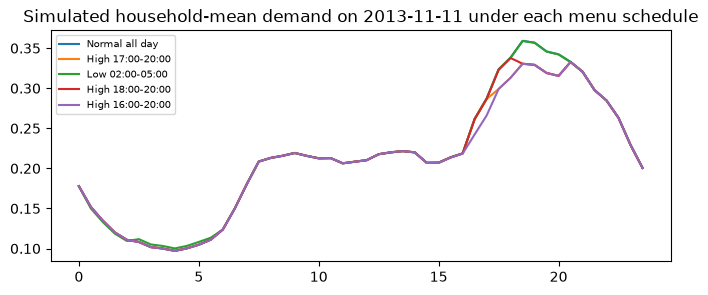

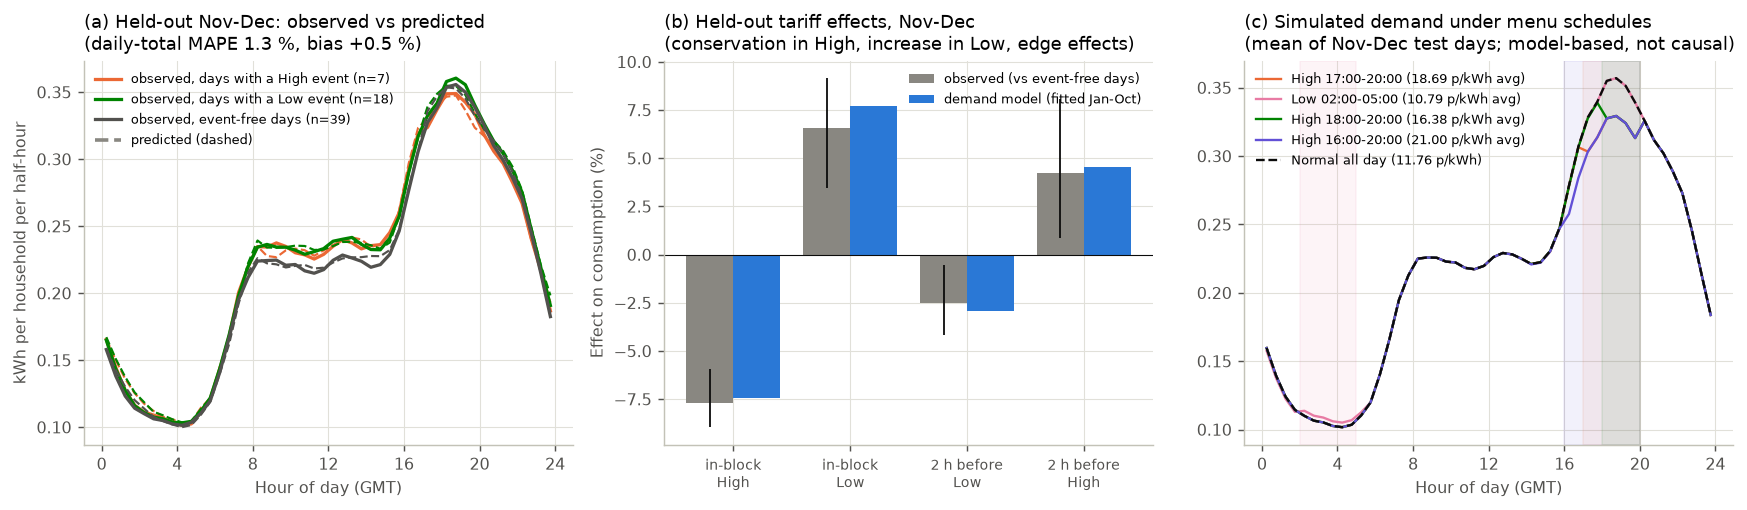

In [19]:
# [EVALUATE] simulate one test day under several schedules with the counterfactual formula (03_policy.World.ratio)
show(S3.World)
fd = M11.Fold(11)                          # Nov-Dec fold: simulator, saved menu, costs, bill quantities (no fitting)
d = fd.fold.test[10]
zero = np.zeros((1, 48))
fig, ax = plt.subplots(figsize=(8, 3))
for s in fd.menu:
    y = np.einsum("c,ch->h", S3.W, S3.YC[:, d] * fd.world.ratio(fd.world.m(s["low"][None], s["high"][None], np.array([d])), np.array([d]))[:, 0])
    ax.plot(hrs, y, label=s["name"])
ax.set_title(f"Simulated household-mean demand on {C.DATES_2013[d].date()} under each menu schedule"); ax.legend(fontsize=7); plt.show()
display(Image(filename=str(RES / "figures" / "fig2_demand_response.png"), width=950))

## 4. Tariff optimisation 🟦

**Menu.** A pool of 98 plausible single-block daily schedules (High 2–4 h, Low 3 or 6 h, kept inside the day) is built by
`candidate_pool`; `select_menu` greedily picks ≤ 6 schedules on **training days** using Lagrangian hindsight costs.

**Day × schedule cost table** (kg CO₂ per household):

$$C_d(z) = \frac{1}{1000}\sum_{t=1}^{48} CI_{d,t}\;\hat y_{d,t}(z),\qquad \hat y_{d,t}(z)=\sum_c w_c\, y^{obs}_{c,d,t}\,e^{m_c(z)_t-m_c(z^{TOU}_d)_t}$$

`costs()` returns it with the realised CI (`E`, used to train trees on past days and to evaluate), with the decision-time
CI forecast and a demand forecast from days d−15…d−2 (`Ef`, used by direct optimisation), and the price paid.

**Average-price feasibility rule** (`feasibility_rule`). Over a period of *D* days with target *T* (historical TOU average
over train+val), day *k* takes the first action *a* of the policy's ranking with
$S_k + p_a + (D-k-1)\,p_{Normal} \le D\,T$, where $S_k$ is the sum of announced daily average prices so far. The all-Normal
day (11.76 ≤ T) is always admissible, so the period constraint is always satisfied. An **override** is a day where the
rule did not take the policy's first choice.

In [20]:
# [SOURCE] menu construction, cost table, feasibility rule
show(PO.candidate_pool); show(S3.select_menu); show(S3.costs); show(PO.feasibility_rule); show(PO.budget_slack)

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 43

def candidate_pool():
    """Plausible single-block schedules (block shapes and times like the 2013 trial's), kept inside slots 3-44 so
    that the 2 h edge effects stay within the day. Returns a list of dicts(name, low, high, price); entry 0 is the
    all-Normal day."""
    blocks = [(None, None)]
    blocks += [((s, s + L - 1), None) for L in (4, 6, 8) for s in range(3, 42, 2) if s + L - 1 <= 44]   # High 2-4 h, 01-20 h
    blocks += [(None, (s, s + L - 1)) for L in (6, 12) for s in range(3, 34, 2) if s + L - 1 <= 44]     # Low 3/6 h, 01-16 h
    blocks += [((hs, hs + 5), (ls, ls + 11)) for hs in (33, 35, 37, 39) for ls in (3, 7)]              # evening High + night Low
    pool = []
    for hb, lb in blocks:
        lo, hi = make_schedule(hb, lb)
        pool.append(dict(name=describe(hb, lb), low=lo, high=hi, price=float(schedule_price(lo, hi).mean())))
    return pool

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 229

def select_menu(fold, world, pool, Mp, target):
    """Greedy forward selection of <= K_MENU schedules on the fold's training days (Lagrangian hindsight costs)."""
    Ep = costs(world, Mp, pool)["E"][fold.train]
    Pp = np.broadcast_to([s["price"] for s in pool], Ep.shape)
    J = Ep + tune_lambda(lambda l: (Ep + l * Pp).argmin(1), Pp, target) * Pp
    menu_idx, gains = [NORMAL], []
    while len(menu_idx) < K_MENU:
        cur = J[:, menu_idx].min(1).sum()
        v, x = min((J[:, menu_idx + [x]].min(1).sum(), x) for x in range(len(pool)) if x not in menu_idx)
        if gains and cur - v < 0.02 * gains[0]:
            break                                          # stop when a schedule adds < 2 % of the first gain
        menu_idx.append(x)
        gains.append(cur - v)
    return menu_idx

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 148

def costs(world, M, menu):
    """Per day and menu action: emissions with the measured factor (E), with the decision-time factor and consumption
    forecasts (Ef), with a perfect factor forecast but forecast consumption, and the average price paid."""
    Y = np.einsum("c,cdh,cdah->dah", W, YC, world.ratio(M, ALL[:, None]))
    det = YC * np.exp(-world.m_hist)                       # consumption forecast: de-tariffed mean of the same day
    base = np.zeros_like(YC)                               # type over days d-15..d-2
    for d in range(365):
        prev = np.arange(max(0, d - 15), max(1, d - 1))
        same = prev[DAYTYPE[prev] == DAYTYPE[d]]
        base[:, d] = det[:, same if len(same) else prev].mean(1)
    Yf = np.einsum("c,cdh,cdah->dah", W, base, np.exp(M))
    p = np.stack([schedule_price(s["low"], s["high"]) for s in menu])          # (A, 48)
    return {"E": np.einsum("dh,dah->da", FAC, Y) / 1000, "Ef": np.einsum("dh,dah->da", FAC_F, Yf) / 1000,
            "Ef_perfect_ci": np.einsum("dh,dah->da", FAC, Yf) / 1000,
            "paid": price_paid(p[None], Y, axis=2), "paid_f": price_paid(p[None], Yf, axis=2)}

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 157

def feasibility_rule(rankings, prices, target):
    """Online average-price rule over an evaluation period of D days (prices: (D, A), known at decision time).
    Day k takes the first action in its ranking such that the target stays attainable if every remaining day were
    all-Normal ('cancel the event'; day k's Normal price stands in for future days'). `rankings` is a list of
    per-day rankings, or a function (k, budget_slack) -> ranking for budget-aware policies.
    Returns (actions, n_adjustments)."""
    P = np.asarray(prices, float)
    D = len(P)
    assert (P[:, NORMAL] <= target + 1e-9).all(), "an all-Normal day must always fit the target"
    S, out, adj = 0.0, [], 0
    for k in range(D):
        rank = rankings(k, budget_slack(S, k, D, target, P[k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if S + P[k, a] + (D - k - 1) * P[k, NORMAL] <= D * target + 1e-9:
                out.append(a)
                adj += i > 0
                S += P[k, a]
                break
    return np.array(out), adj

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 152

def budget_slack(spent, k, D, target, p_normal):
    """Remaining budget per remaining day, as extra price above an all-Normal day (p/kWh), before day k."""
    return (D * target - spent) / (D - k) - p_normal

In [21]:
# [TRAIN — full mode only] select the Nov-Dec menu on the training days; [EVALUATE] build the cost table
saved_menu = [m for m in load_json(MVP / "iai_opt_results_average_mvp.json")["folds"]["11"]["menu"]]
pool = PO.candidate_pool()
print(f"candidate pool: {len(pool)} schedules")
if FULL:
    _fold, _world, menu_live, *_ = M7.fold_inputs(11)
    check("menu selected on training days", [s["name"] for s in menu_live], saved_menu)
else:
    print("[REVIEW] menu not re-selected; saved menu:", saved_menu)
display(pd.DataFrame([{"schedule": s["name"], "time-average price (p/kWh)": s["price"]} for s in fd.menu]))
K = S3.costs(fd.world, fd.world.m_menu(fd.menu), fd.menu)
d0 = fd.fold.test[0]
display(Markdown(f"**Cost table for {C.DATES_2013[d0].date()}** (rows = schedules)"))
display(pd.DataFrame({"E: realised CI x simulated demand (kg)": K["E"][d0], "Ef: forecast CI x forecast demand (kg)": K["Ef"][d0],
                      "price paid (p/kWh)": K["paid"][d0]}, index=[s["name"] for s in fd.menu]))
print("cost table shape (days x schedules):", K["E"].shape, "| target T =", round(fd.target, 3), "p/kWh")

candidate pool: 98 schedules
[REVIEW] menu not re-selected; saved menu: ['Normal all day', 'High 17:00-20:00', 'Low 02:00-05:00', 'High 18:00-20:00', 'High 16:00-20:00']


,schedule,time-average price (p/kWh)
0,Normal all day,11.760
1,High 17:00-20:00,18.690
2,Low 02:00-05:00,10.789
3,High 18:00-20:00,16.380
4,High 16:00-20:00,21.000


**Cost table for 2013-11-01** (rows = schedules)

,E: realised CI x simulated demand (kg),Ef: forecast CI x forecast demand (kg),price paid (p/kWh)
Normal all day,4.136,4.305,11.760
High 17:00-20:00,4.074,4.237,22.101
Low 02:00-05:00,4.143,4.313,11.259
High 18:00-20:00,4.094,4.260,18.706
High 16:00-20:00,4.059,4.220,24.914


cost table shape (days x schedules): (365, 5) | target T = 13.608 p/kWh


## 5. Optimal Policy Trees 🟦 + 🟩

**Decision features** $x_d$ (all known at 12:00 GMT on d−1; `03_policy.features`): forecast-CI summaries (day mean,
16–21 h mean, evening minus night, max − min, start of the dirtiest 3 h), temperature, weekend/holiday, recent consumption
(days d−8…d−2). 🟩 *Leakage fix:* Clement's version used the **realised** temperature of day d; the MVP uses the mean of
the 24 h ending 12:00 on d−1 (`lagged_temperature`, opt-in flag).

**Objective (prescriptive tree, Lecture 11).** Choose a tree $\tau$ of depth ≤ D mapping features to schedules to minimise
the summed **Lagrangian model-based cost** of its prescriptions on the fitting days:

$$\min_{\tau}\ \sum_{d\in\text{fit}} \Big[E_d\big(\tau(x_d)\big) + \lambda\, p\big(\tau(x_d)\big)\Big]$$

λ trades emissions against announced price (so the tree's prescriptions roughly respect the budget); each leaf keeps the
ranking of all actions by summed cost — the fallback order for the feasibility rule.

* 🟦 **Exact solver** (`PolicyTree`): exhaustive search of all thresholds at the last level, 12 quantile thresholds above.
* 🟩 **IAI** `OptimalTreePolicyMinimizer` (max_depth, minbucket 10, cp 0) on the same features and costs (`07_iai_fit.jl`).

**Selection protocol** (both solvers): fit on training days for depth ∈ {1, 2, 3} × λ grid → roll the tree through the
feasibility rule on **validation** days → keep the lowest validation emissions (ties: shallower, fewer overrides) → refit on
train + validation → evaluate **once** on the test window.

In [22]:
# [SOURCE] decision features (incl. the leak-free temperature) and the exact prescriptive tree
show(S3.lagged_temperature); show(S3.features); show(PO.PolicyTree)
display(pd.DataFrame(S3.X[fd.fold.test[:5]], columns=list(S3.FEATURES), index=C.DATES_2013[fd.fold.test[:5]].date).T)

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 89

def lagged_temperature(temp):
    """Mean temperature of the 48 half-hours ending 12:00 GMT on d-1 (slot 24 of d-1 ends at 12:00), i.e. the
    information available at the day-ahead announcement. 2013-01-01 has no such data (ERA5 starts 2013-01-01) and
    takes 2013-01-02's value; 2013-01-02 uses the 25 available half-hours (both are training days)."""
    flat = temp.ravel()
    out = np.empty(len(temp))
    for d in range(len(temp)):
        end = (d - 1) * H + 24
        out[d] = flat[max(0, end - 47): end + 1].mean() if end >= 0 else np.nan
    out[0] = out[1]
    return out

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 102

def features():
    temp = load_temps_2013()
    win = np.stack([np.convolve(r, np.ones(6), "valid") for r in CIF])
    daily = YALL.mean(1)
    f = np.zeros((365, len(FEATURES)))
    f[:, 0] = CIF.mean(1)
    f[:, 1] = CIF[:, hours(16, 21)].mean(1)
    f[:, 2] = f[:, 1] - CIF[:, hours(0, 6)].mean(1)
    f[:, 3] = CIF.max(1) - CIF.min(1)
    f[:, 4] = (win.argmax(1) - 1) / 2.0                     # window starting at slot i begins at (i-1)/2 h GMT
    f[:, 5] = temp.mean(1) if TEMPERATURE == "realised" else lagged_temperature(temp)
    f[:, 6] = DAYTYPE
    f[:, 7] = [daily[max(0, d - 8): max(1, d - 1)].mean() for d in range(365)]   # days d-8..d-2
    return f

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 59

class PolicyTree:
    """Exact optimal prescriptive tree of a given depth minimising the summed cost of the prescribed actions.
    Split thresholds: all midpoints at the last level, `n_thresh` quantiles above it (n_thresh=None: every threshold at
    every level, i.e. the global optimum). Each leaf keeps the ranking of the actions by their summed training cost
    (the fallback order used by the feasibility rule)."""

    def __init__(self, depth, min_leaf=10, n_thresh=12, feature_names=None):
        self.depth, self.min_leaf, self.n_thresh, self.names = depth, min_leaf, n_thresh, feature_names

    def fit(self, X, C):
        self.X, self.C = np.asarray(X, float), np.asarray(C, float)
        self.root = self._build(np.arange(len(X)), self.depth)
        del self.X, self.C
        return self

    def _leaf(self, idx):
        tot = self.C[idx].sum(0)
        return {"leaf": True, "action": int(tot.argmin()), "n": int(len(idx)), "ranking": np.argsort(tot, kind="stable").tolist()}

    def _stump(self, idx, leaf):
        """Best depth-1 split of idx, vectorised over features: (cost, feature, threshold)."""
        Xs, Cs = self.X[idx], self.C[idx]
        O = np.argsort(Xs, axis=0, kind="stable")
        xs = np.take_along_axis(Xs, O, 0)
        cum = np.cumsum(Cs[O], axis=0)                       # (n, p, A)
        k = np.arange(self.min_leaf - 1, len(idx) - self.min_leaf)
        s = cum[k].min(-1) + (cum[-1][None] - cum[k]).min(-1)  # (len k, p)
        s[~(xs[k] < xs[k + 1])] = np.inf
        i, j = np.unravel_index(int(np.argmin(s)), s.shape)
        if not s[i, j] < leaf - 1e-9:
            return leaf, None, None
        return float(s[i, j]), int(j), float(0.5 * (xs[k[i], j] + xs[k[i] + 1, j]))

    def _search(self, idx, depth):
        """Optimal (cost, feature, threshold) of a depth-`depth` tree on idx (feature None = leaf)."""
        rowmin = self.C[idx].min(1)
        leaf, lower_bound = self.C[idx].sum(0).min(), rowmin.sum()
        if depth == 0 or len(idx) < 2 * self.min_leaf or leaf - lower_bound < 1e-9:
            return leaf, None, None
        if depth == 1:
            return self._stump(idx, leaf)
        best = (leaf, None, None)
        Xs = self.X[idx]
        if self.n_thresh:
            Q = np.quantile(Xs, np.linspace(0, 1, self.n_thresh + 2)[1:-1], axis=0, method="lower")
            thresholds = [np.unique(Q[:, j]) for j in range(Xs.shape[1])]
        else:
            thresholds = [np.unique(Xs[:, j])[:-1] for j in range(Xs.shape[1])]
        for j in range(Xs.shape[1]):
            for t in thresholds[j]:
                m = Xs[:, j] <= t
                nl = int(m.sum())
                if nl < self.min_leaf or len(idx) - nl < self.min_leaf or lower_bound >= best[0] - 1e-9:
                    continue
                cl = self._search(idx[m], depth - 1)[0]
                if cl + rowmin[~m].sum() >= best[0] - 1e-9:
                    continue
                cr = self._search(idx[~m], depth - 1)[0]
                if cl + cr < best[0] - 1e-9:
                    best = (cl + cr, j, float(t))
        return best

    def _build(self, idx, depth):
        _, j, t = self._search(idx, depth)
        if j is None:
            return self._leaf(idx)
        m = self.X[idx, j] <= t
        return {"leaf": False, "feature": j, "threshold": t, "n": int(len(idx)),
                "left": self._build(idx[m], depth - 1), "right": self._build(idx[~m], depth - 1)}

    def leaf_of(self, x):
        node = self.root
        while not node["leaf"]:
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node

    def rankings(self, X):
        return [self.leaf_of(x)["ranking"] for x in np.asarray(X, float)]

    def n_leaves(self, node=None):
        node = self.root if node is None else node
        return 1 if node["leaf"] else self.n_leaves(node["left"]) + self.n_leaves(node["right"])

    def text(self, action_names, node=None, indent=""):
    

,2013-11-01,2013-11-02,2013-11-03,2013-11-04,2013-11-05
"forecast CI, day mean (g/kWh)",488.269,460.350,437.493,443.115,491.695
"forecast CI, 16:00-21:00 (g/kWh)",488.577,468.364,440.841,472.702,493.467
"forecast CI, evening minus night (g/kWh)",9.671,25.380,6.351,89.997,11.663
"forecast CI, max - min (g/kWh)",37.770,50.957,22.608,115.450,43.051
"forecast dirtiest 3 h, start hour (GMT)",6.500,6.500,12.000,19.000,20.500
"temperature, 24 h to 12:00 on d-1 (C)",12.345,12.073,11.196,10.035,7.941
weekend or holiday,0.000,1.000,1.000,0.000,0.000
recent consumption (kWh/half-hour),0.188,0.190,0.191,0.192,0.195


In [23]:
# [SOURCE] IAI fitting script and the Python side (export, run, read the fitted tree, same selection protocol)
show_file("carbon_tariff_pipeline/scripts/07_iai_fit.jl", language="julia")
show(M7.export); show(M7.iai_fitted); show(M7.run_fold)

**Source:** `carbon_tariff_pipeline/scripts/07_iai_fit.jl` lines 1–56

# MVP Step 4 (IAI): fit Interpretable AI Optimal Policy Trees on the inputs written by scripts/07_iai_opt.py.
#
#     julia +1.12.6/IAI/3.2.2 scripts/07_iai_fit.jl <dir>
#
# <dir>/cases.csv lists one fit per row: case, fold, fitset (tr or tv), depth, lambda, minbucket.
# For fold F the inputs are <dir>/F_X_<set>.csv (features, columns f0..f7) and <dir>/F_E_<set>.csv (realised model-based
# emissions per action, kg CO2/household, columns a0..aA-1), plus <dir>/F_price.csv (time-average price of each action).
# Action costs = E + lambda * price (the same Lagrangian costs the pipeline's exact tree is fitted on).
# Each fit uses OptimalTreePolicyMinimizer(max_depth = depth, minbucket, cp = 0, random_seed = 1): no complexity penalty,
# so depth is the only complexity control (chosen on validation in Python, as for the exact tree).
# Writes per case: <case>_rank_fit.csv (treatment ranking of each fitting row, best first),
# <case>_rank_eval.csv (ranking of each evaluation row: validation rows for fitset tr, test rows for fitset tv),
# <case>_nodes.csv (tree structure) and <case>_time.csv.
# Note: the IAI system image preloads the IAI module, so it is not listed in `using`.
using CSV, DataFrames

dir = ARGS[1]
cases = CSV.read(joinpath(dir, "cases.csv"), DataFrame)
cache = Dict{String,DataFrame}()
load(name) = get!(() -> CSV.read(joinpath(dir, name), DataFrame), cache, name)
ranks_to_df(r) = DataFrame(Matrix{Int}(parse.(Int, chop.(string.(r), head=1, tail=0))), :auto)

for row in eachrow(cases)
    c, f, s = String(row.case), String(row.fold), String(row.fitset)
    X = load("$(f)_X_$(s).csv")
    E = load("$(f)_E_$(s).csv")
    price = Vector{Float64}(load("$(f)_price.csv").price)
    C = copy(E)
    for (j, nm) in enumerate(names(C))
        C[!, nm] = E[!, nm] .+ row.lambda .* price[j]
    end
    Xeval = load("$(f)_X_$(s == "tr" ? "va" : "te").csv")
    lnr = IAI.OptimalTreePolicyMinimizer(max_depth=row.depth, minbucket=row.minbucket, cp=0.0, random_seed=1)
    t0 = time()
    IAI.fit!(lnr, X, C)
    secs = time() - t0
    CSV.write(joinpath(dir, "$(c)_rank_fit.csv"), ranks_to_df(IAI.predict_treatment_rank(lnr, X)))
    CSV.write(joinpath(dir, "$(c)_rank_eval.csv"), ranks_to_df(IAI.predict_treatment_rank(lnr, Xeval)))
    nodes = DataFrame(node=Int[], leaf=Bool[], feature=String[], threshold=Float64[], lower=Int[], upper=Int[],
                      n=Int[], ranking=String[])
    for t in 1:IAI.get_num_nodes(lnr)
        if IAI.is_leaf(lnr, t)
            push!(nodes, (t, true, "", NaN, 0, 0, IAI.get_num_samples(lnr, t),
                          join(string.(IAI.get_policy_treatment_rank(lnr, t)), " ")))
        else
            IAI.is_parallel_split(lnr, t) || error("case $c, node $t: only parallel (one-feature) splits are expected")
            push!(nodes, (t, false, string(IAI.get_split_feature(lnr, t)), Float64(IAI.get_split_threshold(lnr, t)),
                          IAI.get_lower_child(lnr, t), IAI.get_upper_child(lnr, t), IAI.get_num_samples(lnr, t), ""))
        end
    end
    CSV.write(joinpath(dir, "$(c)_nodes.csv"), nodes)
    CSV.write(joinpath(dir, "$(c)_time.csv"), DataFrame(seconds=[secs]))
    println("$c: depth $(row.depth), lambda $(row.lambda), $(IAI.get_num_nodes(lnr)) nodes, $(round(secs, digits=2)) s")
    flush(stdout)
end
println("done")

**Source:** `carbon_tariff_pipeline/scripts/07_iai_opt.py` line 79

def export(tag, fold, E, P):
    sets = {"tr": fold.train, "tv": fold.trainval, "va": fold.val, "te": fold.test}
    for s, days in sets.items():
        pd.DataFrame(S3.X[days], columns=[f"f{j}" for j in range(len(FEATS))]).to_csv(IAI_DIR / f"{tag}_X_{s}.csv", index=False)
        if s in ("tr", "tv"):
            pd.DataFrame(E[days], columns=[f"a{a}" for a in range(E.shape[1])]).to_csv(IAI_DIR / f"{tag}_E_{s}.csv", index=False)
    pd.DataFrame({"price": P[0]}).to_csv(IAI_DIR / f"{tag}_price.csv", index=False)
    return [{"case": f"{tag}_{s}_d{d}_l{li:02d}", "fold": tag, "fitset": s, "depth": d, "lambda": lam, "minbucket": MIN_LEAF}
            for s in ("tr", "tv") for d in DEPTHS for li, lam in enumerate(S3.LAMBDAS)]

**Source:** `carbon_tariff_pipeline/scripts/07_iai_opt.py` line 149

def iai_fitted(case, X_fit):
    """(root, rankings function) of an IAI fit, after checking that the node table reproduces IAI's predictions."""
    root, _ = iai_tree(case)
    ranks_fit = pd.read_csv(IAI_DIR / f"{case}_rank_fit.csv").to_numpy(int)
    for strict in (True, False):
        if all(route(root, x, strict)["ranking"][0] == r[0] for x, r in zip(X_fit, ranks_fit)):
            mark_strict(root, strict)
            return root, (lambda X, s=strict: [route(root, x, s)["ranking"] for x in np.asarray(X, float)])
    raise ValueError(f"{case}: the IAI node table does not reproduce IAI's own predictions")

**Source:** `carbon_tariff_pipeline/scripts/07_iai_opt.py` line 175

def run_fold(mm, iai_ok):
    fold, world, menu, E, P, target = fold_inputs(mm)
    names = [s["name"] for s in menu]
    tag = fold.label.replace("-", "")
    tr, va, tv, te = fold.train, fold.val, fold.trainval, fold.test
    log(f"fold {fold.label}: menu {names}, target {target:.3f} p/kWh, days train/val/test {len(tr)}/{len(va)}/{len(te)}")
    res = {"label": fold.label, "target": target, "historical_test_price": float(S3.PRICE_H[te].mean()), "menu": names,
           "menu_prices": [s["price"] for s in menu], "grid": {}, "chosen": {}, "by_depth": {}}
    for solver in SOLVERS:
        if solver == "iai" and not iai_ok:
            continue
        grid, fitted = [], {}
        for d in DEPTHS:
            for li, lam in enumerate(S3.LAMBDAS):
                C_tr = E[tr] + lam * P[tr]
                if solver == "exact":
                    tree = PolicyTree(d, min_leaf=MIN_LEAF, feature_names=FEATS).fit(S3.X[tr], C_tr)
                    root, rank_fn = tree.root, tree.rankings
                else:
                    root, rank_fn = iai_fitted(f"{tag}_tr_d{d}_l{li:02d}", S3.X[tr])
                first = np.array([r[0] for r in rank_fn(S3.X[tr])])
                acts, adj = feasibility_rule(rank_fn(S3.X[va]), P[va], target)
                grid.append({"depth": d, "lambda": lam, "li": li, "val_emissions_kg": float(E[va, acts].sum()), "adjustments": adj,
                             "leaves": n_leaves(root), "train_cost": float(C_tr[np.arange(len(tr)), first].sum())})
        pick = pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], -g["lambda"]))
        res["grid"][solver] = grid
        res["chosen"][solver] = {"depth": pick["depth"], "lambda": pick["lambda"]}
        res["by_depth"][solver] = {}
        for d in DEPTHS:
            g = pick_near_best([x for x in grid if x["depth"] == d], lambda x: (x["adjustments"], -x["lambda"]))
            C_tv = E[tv] + g["lambda"] * P[tv]
            if solver == "exact":
                tree = PolicyTree(d, min_leaf=MIN_LEAF, feature_names=FEATS).fit(S3.X[tv], C_tv)
                root, rank_fn = tree.root, tree.rankings
            else:
                root, rank_fn = iai_fitted(f"{tag}_tv_d{d}_l{g['li']:02d}", S3.X[tv])
            first = np.array([r[0] for r in rank_fn(S3.X[tv])])
            entry = {"lambda": g["lambda"], "val_emissions_kg": g["val_emissions_kg"], "val_adjustments": g["adjustments"],
                     "trainval_cost": float(C_tv[np.arange(len(tv)), first].sum()),
                     "trainval_single_action_cost": float(C_tv.sum(0).min()), "trainval_per_day_best_cost": float(C_tv.min(1).sum()),
                     "leaves": n_leaves(root), "tree": root, "text": tree_text(root, names),
                     "test": evaluate_test(fold, world, menu, P, target, rank_fn(S3.X[te])),
                     "chosen": d == pick["depth"]}
            res["by_depth"][solver][d] = entry
            t = entry["test"]
            log(f"  {solver} depth {d}: lambda {g['lambda']}, val {g['val_emissions_kg']:.3f} kg (adj {g['adjustments']}), "
                f"leaves {entry['leaves']}, test reduction {t['emissions_reduction_pct']:+.3f}%, overrides {t['overrides']}/{t['n_days']}"
                + (" <- chosen" if entry["chosen"] else ""))
    if iai_ok:
        res["agreement_test_prescriptions_pct"] = {
            d: float(100 * np.mean(np.array(res["by_depth"]["exact"][d]["test"]["prescribed"])
                                   == np.array(res["by_depth"]["iai"][d]["test"]["prescribed"]))) for d in DEPTHS}
    return res

In [24]:
# [TRAIN — full mode only] exact-tree grid search + IAI fits for the Nov-Dec fold (07_iai_opt.run_fold, IAI in a temp folder)
s7 = load_json(MVP / "iai_opt_results_average_mvp.json")["folds"]["11"]
if FULL and JULIA:
    with tempfile.TemporaryDirectory(prefix="iai_") as tmp:
        old = M7.IAI_DIR; M7.IAI_DIR = Path(tmp)
        try:
            f_, w_, m_, E_, P_, _ = M7.fold_inputs(11)
            M7.run_iai(M7.export("NovDec", f_, E_, P_))          # 78 IAI fits: 2 fit sets x 3 depths x 13 lambdas
            live7 = M7.run_fold(11, True)                         # exact grid + IAI selection, refit, test evaluation
        finally:
            M7.IAI_DIR = old
    for s in ("exact", "iai"):
        check(f"{s}: chosen (depth, lambda)", live7["chosen"][s], s7["chosen"][s])
        dsel = live7["chosen"][s]["depth"]
        check(f"{s}: test reduction (%)", live7["by_depth"][s][dsel]["test"]["emissions_reduction_pct"], s7["by_depth"][s][str(dsel)]["test"]["emissions_reduction_pct"])
elif FULL:
    print("Julia/IAI not available: run_mvp.py ran the exact solver only")
else:
    print("[REVIEW] no tree fitted; loading the saved chosen trees (exact and IAI) from results/mvp/outputs/iai_opt_results_average_mvp.json")

[REVIEW] no tree fitted; loading the saved chosen trees (exact and IAI) from results/mvp/outputs/iai_opt_results_average_mvp.json


In [25]:
# [EVALUATE] roll the chosen trees through the feasibility rule on the 61 test days and score them with the simulator
te = fd.fold.test
def evaluate_static(rankings):
    acts, adj = PO.feasibility_rule(rankings, fd.P[te], fd.target)
    low = np.stack([fd.menu[a]["low"] for a in acts]); high = np.stack([fd.menu[a]["high"] for a in acts])
    s = S3.summarise(fd.fold, S3.evaluate(fd.fold, fd.world, low, high))
    return acts, adj, s
exact_root = s7["by_depth"]["exact"][str(s7["chosen"]["exact"]["depth"])]["tree"]
exact_tree = PO.PolicyTree(s7["chosen"]["exact"]["depth"], feature_names=list(S3.FEATURES)); exact_tree.root = exact_root
iai_root = s7["by_depth"]["iai"][str(s7["chosen"]["iai"]["depth"])]["tree"]
iai_rank = lambda X: [M7.route(iai_root, x, iai_root.get("strict", False))["ranking"] for x in X]
for name, rk, key in (("exact tree", exact_tree.rankings, "exact"), ("IAI OPT", iai_rank, "iai")):
    acts, adj, s = evaluate_static(rk(S3.X[te]))
    print(f"{name}: depth {s7['chosen'][key]['depth']}, test reduction {-s['emissions_change_pct']:.3f} %, avg price {s['mean_price']:.3f}, "
          f"bill {s['bill_change_mean_pct']:+.1f} %, overrides {adj}/61, High days {int(sum('High' in fd.menu[a]['name'] for a in acts))}")
    check(f"{name} test reduction vs saved", -s["emissions_change_pct"], s7["by_depth"][key][str(s7["chosen"][key]["depth"])]["test"]["emissions_reduction_pct"])
print("\nExact tree:\n" + exact_tree.text([m["name"] for m in fd.menu]))
print("IAI tree:\n" + M7.tree_text(iai_root, [m["name"] for m in fd.menu]))

exact tree: depth 2, test reduction 0.763 %, avg price 13.578, bill +8.2 %, overrides 49/61, High days 12
[MATCH] exact tree test reduction vs saved: got 0.762629 | saved 0.762629
IAI OPT: depth 3, test reduction 0.796 %, avg price 13.578, bill +9.5 %, overrides 42/61, High days 19
[MATCH] IAI OPT test reduction vs saved: got 0.795615 | saved 0.795615

Exact tree:
if forecast CI, 16:00-21:00 (g/kWh) <= 475:
    if recent consumption (kWh/half-hour) <= 0.167:
        -> Normal all day  (n=84)
    else:
        -> High 16:00-20:00  (n=33)
else:
    if recent consumption (kWh/half-hour) <= 0.176:
        -> High 17:00-20:00  (n=59)
    else:
        -> High 16:00-20:00  (n=128)

IAI tree:
if recent consumption (kWh/half-hour) < 0.1754:
    if temperature, 24 h to 12:00 on d-1 (C) < 13.14:
        if forecast CI, max - min (g/kWh) < 46.13:
            -> Low 02:00-05:00  (n=25)
        else:
            -> High 18:00-20:00  (n=18)
    else:
        if recent consumption (kWh/half-hour) < 0

**Policy evaluation.** The test score uses realised average CI × simulated demand under the realised schedule sequence (after
the feasibility rule), relative to the historical TOU on the same days. Note the overrides: the trees prescribe the 4-h
evening High block almost every day, and the rule cancels it once the price budget is used up — the motivation for §6.

In [26]:
# [SAVED RESULT] Nov-Dec comparison of all policies and the solver comparison across windows
display(pd.read_csv(RES / "tables" / "policy_comparison_main.csv")[["Policy", "Reduction vs TOU (%)", "95% simulator CI (%)", "Avg announced price (p/kWh)", "Mean bill change (%)", "Feasibility overrides (of 61)"]])
ive = pd.read_csv(RES / "tables" / "iai_vs_exact.csv")
display(ive[ive["Selected on val"] == "yes"][["Test window", "Solver", "Depth", "Leaves", "Test reduction (%)", "Overrides (of test days)"]])

,Policy,Reduction vs TOU (%),95% simulator CI (%),Avg announced price (p/kWh),Mean bill change (%),Feasibility overrides (of 61)
0,A. Historical TOU (2013),-0.000,NaN,12.795,0.000,-
1,B. Carbon-based heuristic,-0.290,"[-0.42, -0.16]",13.606,4.680,0 (daily rule meets target)
2,C. Direct model-based optimisation,0.841,"[0.75, 0.93]",13.594,14.024,43
3,D. Policy tree (exact solver),0.763,"[0.67, 0.85]",13.578,8.212,49
4,D'. IAI Optimal Policy Tree,0.796,NaN,13.578,9.513,42
5,Ext. Budget-aware policy tree,0.803,"[0.71, 0.89]",13.575,14.413,3
6,Ref. Oracle (perfect hindsight),0.890,"[0.80, 0.97]",13.551,14.899,n/a (hindsight)


,Test window,Solver,Depth,Leaves,Test reduction (%),Overrides (of test days)
0,May-Jun,Exact tree,1,2,-0.379,0/61
3,May-Jun,IAI OPT,1,2,-0.379,0/61
6,Jul-Aug,Exact tree,1,2,0.302,0/62
9,Jul-Aug,IAI OPT,1,2,0.302,0/62
12,Sep-Oct,Exact tree,1,2,0.495,45/61
15,Sep-Oct,IAI OPT,1,2,0.495,45/61
19,Nov-Dec,Exact tree,2,4,0.763,49/61
23,Nov-Dec,IAI OPT,3,7,0.796,42/61


## 6. Budget-aware policy trees 🟦 + 🟩

**Problem.** A fixed tree ignores how much of the price budget is left, so the feasibility rule decides most days.

**State variable.** Before announcing day *k*, the remaining budget per remaining day, above an all-Normal day, is

$$s_k = \frac{D\,T - S_k}{D-k} - p_{Normal}\qquad(\texttt{budget\_slack})$$

**Training set** (`paced_training_set`): every fitting day is repeated at 9 budget levels $s \in\{0, 0.25, \dots, 9.5\}$;
the level is appended as a feature and the row's costs are $E_d + \lambda(s)\,p$, where $\lambda(s)$ is the multiplier that
makes the per-day argmin spend that level on the fitting days. The tree therefore learns *when* spending is worthwhile.
At decision time the feasibility rule passes the current $s_k$ to the tree (it remains as a safety net).

**Alternative — pacing rule** 🟩 (`pacing_rule`): keep the fixed tree but add a cumulative pace
$S_k + p_a \le (k+1)\,T + B$ (B chosen on validation; B = ∞ is the original rule). This spreads events in time but
cannot make the tree's prescriptions better.

In [27]:
# [SOURCE] budget-aware training set, the pacing rule and how 10_pacing_experiment selects a budget-aware tree
show(S3.paced_training_set); show(PO.pacing_rule); show(M10.select_budget_aware); show(M10.budget_aware_tree)

**Source:** `carbon_tariff_pipeline/scripts/03_policy.py` line 245

def paced_training_set(E, P, days):
    """Budget-aware tree training rows: each of `days` repeated at every SLACK_GRID level, with the level as an extra
    feature and costs E + lambda * P, lambda being the multiplier that makes the per-day argmin spend that level on
    average over `days`. Returns (X, C, lambdas)."""
    pn = float(P[days][:, NORMAL].mean())
    lams = np.array([tune_lambda(lambda l: (E[days] + l * P[days]).argmin(1), P[days], pn + sl) for sl in SLACK_GRID])
    Xa = np.vstack([np.column_stack([X[days], np.full(len(days), sl)]) for sl in SLACK_GRID])
    Ca = np.vstack([E[days] + lam * P[days] for lam in lams])
    return Xa, Ca, lams

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 178

def pacing_rule(rankings, prices, target, borrow):
    """Budget-PACING version of feasibility_rule (added 2026-11-14 for the pacing experiment; feasibility_rule is
    unchanged). Day k takes the first action in its ranking that satisfies BOTH
      (1) terminal feasibility, as in feasibility_rule: S_k + p_a + (D-k-1) * p_Normal <= D * T, and
      (2) a cumulative pace:  S_k + p_a <= (k+1) * T + borrow,
    where S_k = sum of announced time-average prices of days 0..k-1. `borrow` (p/kWh x days) is how far the cumulative
    spend may run ahead of an even spend of the target: borrow = 0 is strict "save first, then spend" (an event costing
    p_a > T is only allowed once earlier cheaper days have banked p_a - T); borrow = inf gives feasibility_rule exactly.
    Only information known at the announcement is used: past announced prices, k, D, T and the menu prices.
    The all-Normal day always satisfies (1) and (2) (p_Normal <= T and, by induction, S_k <= k*T + borrow), so the rule
    never fails. Same interface and return value as feasibility_rule: (actions, n_adjustments)."""
    P = np.asarray(prices, float)
    D = len(P)
    assert (P[:, NORMAL] <= target + 1e-9).all(), "an all-Normal day must always fit the target"
    S, out, adj = 0.0, [], 0
    for k in range(D):
        rank = rankings(k, budget_slack(S, k, D, target, P[k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if (S + P[k, a] + (D - k - 1) * P[k, NORMAL] <= D * target + 1e-9
                    and S + P[k, a] <= (k + 1) * target + borrow + 1e-9):
                out.append(a)
                adj += i > 0
                S += P[k, a]
                break
    return np.array(out), adj

**Source:** `carbon_tariff_pipeline/scripts/10_pacing_experiment.py` line 211

def select_budget_aware(fd, solver, rule):
    f = fd.fold
    Xtr, Ctr, _ = S3.paced_training_set(fd.E, fd.P, f.train)
    grid = []
    for d in DEPTHS:
        _, one = budget_aware_tree(fd, solver, d, "tr", Xtr, Ctr)
        for g in rollout_grid(fd, paced_rank(fd, one, f.val), rule):
            grid.append({"depth": d, "lambda": None, **g})
    pick = pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], g["borrow"] or 0.0))
    Xtv, Ctv, lams = S3.paced_training_set(fd.E, fd.P, f.trainval)
    root, one = budget_aware_tree(fd, solver, pick["depth"], "tv", Xtv, Ctv)
    return pick, root, one, lams

**Source:** `carbon_tariff_pipeline/scripts/10_pacing_experiment.py` line 170

def budget_aware_tree(fd, solver, depth, days_fit, Xa, Ca):
    if solver == "exact":
        t = PolicyTree(depth, min_leaf=MIN_LEAF, feature_names=PACED_FEATS).fit(Xa, Ca)
        return t.root, (lambda x, t=t: t.leaf_of(x)["ranking"])
    old = M7.IAI_DIR
    M7.IAI_DIR = PACED_DIR
    try:
        root, rank_fn = M7.iai_fitted(f"{fd.tag}_{days_fit}_d{depth}_l00", Xa)
    finally:
        M7.IAI_DIR = old
    return root, (lambda x: rank_fn(np.asarray(x, float)[None])[0])

In [28]:
# [TRAIN — full mode only] exact budget-aware tree (depth chosen on validation), and IAI budget-aware fits (temp folder)
step3 = load_json(MVP / "step3_results_average_mvp.json")
pac = load_json(RES / "pacing" / "pacing_results.json")["folds"]["11"]["policies"]
Xa, Ca, lams = S3.paced_training_set(fd.E, fd.P, fd.fold.trainval)
print(f"budget-aware training set: {Xa.shape[0]} rows = {len(fd.fold.trainval)} days x {len(S3.SLACK_GRID)} budget levels; {Xa.shape[1]} features")
print("lambda(s) per budget level:", {s_: round(float(l_), 4) for s_, l_ in zip(S3.SLACK_GRID, lams)})
if FULL:
    pick_e, root_e, one_e, _ = M10.select_budget_aware(fd, "exact", "original")
    check("exact budget-aware tree identical to Step 3's", root_e, step3["paced_tree"])
    if JULIA:
        with tempfile.TemporaryDirectory(prefix="iai_ba_") as tmp:
            old = M10.PACED_DIR; M10.PACED_DIR = Path(tmp)
            try:
                M10.export_budget_aware([fd])                      # 6 IAI fits (train / train+val x depth 1-3)
                pick_i, root_i, one_i, _ = M10.select_budget_aware(fd, "iai", "original")
            finally:
                M10.PACED_DIR = old
else:
    root_e = step3["paced_tree"]
    _t = PO.PolicyTree(1); _t.root = root_e; one_e = lambda x: _t.leaf_of(x)["ranking"]
    print("[REVIEW] no tree fitted; exact budget-aware tree loaded from step3_results_average_mvp.json")
    if (M10.PACED_DIR / "cases.csv").exists():
        pick_i, root_i, one_i, _ = M10.select_budget_aware(fd, "iai", "original")   # reads the SAVED IAI fits; validation replay only
        print("[REVIEW] IAI budget-aware trees read from the saved fits in", M10.PACED_DIR.relative_to(ROOT))
    else:
        one_i = None; print("saved IAI budget-aware fits not present (gitignored); run the pacing stage")

budget-aware training set: 2736 rows = 304 days x 9 budget levels; 9 features
lambda(s) per budget level: {0.0: 0.0124, 0.25: 0.0121, 0.5: 0.0118, 1.0: 0.0111, 1.5: 0.0105, 2.0: 0.0097, 3.0: 0.0089, 5.0: 0.0076, 9.5: 0.0}
[REVIEW] no tree fitted; exact budget-aware tree loaded from step3_results_average_mvp.json
[REVIEW] IAI budget-aware trees read from the saved fits in results/mvp/outputs/iai_budgetaware_average_mvp


In [29]:
# [EVALUATE] budget-aware trees under the original rule (state passed to the tree each day) vs the fixed tree with pacing
names = [m["name"] for m in fd.menu]
def evaluate_rule(rankings, rule="original", B=None):
    acts, adj, first = M10.run_rule(rule, rankings, fd.P[te], fd.target, B)
    return M10.evaluate(fd, acts, first, adj, fd.target)
rows_ = []
for label, rk, rule, B, key in (
        ("exact tree (fixed), original rule", exact_tree.rankings(S3.X[te]), "original", None, "exact tree (selected under original rule) | original rule"),
        ("exact tree (fixed), pacing rule", exact_tree.rankings(S3.X[te]), "pacing", pac["exact tree (selected under original rule) | pacing rule"]["selection"]["borrow"], "exact tree (selected under original rule) | pacing rule"),
        ("exact budget-aware tree, original rule", M10.paced_rank(fd, one_e, te), "original", None, "exact budget-aware tree | original rule"),
        *((("IAI budget-aware tree, original rule", M10.paced_rank(fd, one_i, te), "original", None, "iai budget-aware tree | original rule"),) if one_i else ())):
    e = evaluate_rule(rk, rule, B)
    rows_.append({"policy": label, "B": B, "reduction (%)": e["emissions_reduction_pct"], "bill change (%)": e["bill_change_mean_pct"],
                  "overrides": e["overrides"], "High days by quarter": "/".join(map(str, e["high_days_by_quarter"]))})
    check(label, e["emissions_reduction_pct"], pac[key]["main"]["emissions_reduction_pct"])
display(pd.DataFrame(rows_))
print("Exact budget-aware tree (Nov-Dec):\n" + M10.tree_text(root_e, names, list(S3.PACED_FEATURES)))

[MATCH] exact tree (fixed), original rule: got 0.762629 | saved 0.762629
[MATCH] exact tree (fixed), pacing rule: got 0.814967 | saved 0.814967
[MATCH] exact budget-aware tree, original rule: got 0.803008 | saved 0.803008
[MATCH] IAI budget-aware tree, original rule: got 0.864579 | saved 0.864579


,policy,B,reduction (%),bill change (%),overrides,High days by quarter
0,"exact tree (fixed), original rule",NaN,0.763,8.212,49,12/0/0/0
1,"exact tree (fixed), pacing rule",5.0,0.815,10.380,61,7/6/6/5
2,"exact budget-aware tree, original rule",NaN,0.803,14.413,3,0/2/2/13
3,"IAI budget-aware tree, original rule",NaN,0.865,14.732,17,0/9/11/3


Exact budget-aware tree (Nov-Dec):
if recent consumption (kWh/half-hour) <= 0.2239:
    if remaining budget per remaining day (p/kWh above Normal) <= 7.25:
        -> Low 02:00-05:00  (n=1688)
    else:
        -> High 16:00-20:00  (n=211)
else:
    if remaining budget per remaining day (p/kWh above Normal) <= 1.75:
        -> High 18:00-20:00  (n=465)
    else:
        -> High 16:00-20:00  (n=372)



,policy,rule,mean_reduction_pct,min_reduction_pct,mean_bill_change_pct,mean_overrides
0,exact tree (selected under original rule),original rule,0.295,-0.379,-4.293,23.50
1,exact tree (selected under original rule),pacing rule,0.325,-0.379,-3.196,30.50
2,exact tree (re-selected under pacing),pacing rule,0.325,-0.379,-3.196,30.50
3,iai tree (selected under original rule),original rule,0.303,-0.379,-3.968,21.75
4,iai tree (selected under original rule),pacing rule,0.326,-0.379,-3.054,29.50
5,iai tree (re-selected under pacing),pacing rule,0.326,-0.379,-3.054,29.50
6,exact budget-aware tree,original rule,0.585,0.264,10.241,1.25
7,exact budget-aware tree,pacing rule,0.587,0.264,10.277,1.25
8,iai budget-aware tree,original rule,0.610,0.264,10.762,5.00
9,iai budget-aware tree,pacing rule,0.602,0.264,10.307,8.50


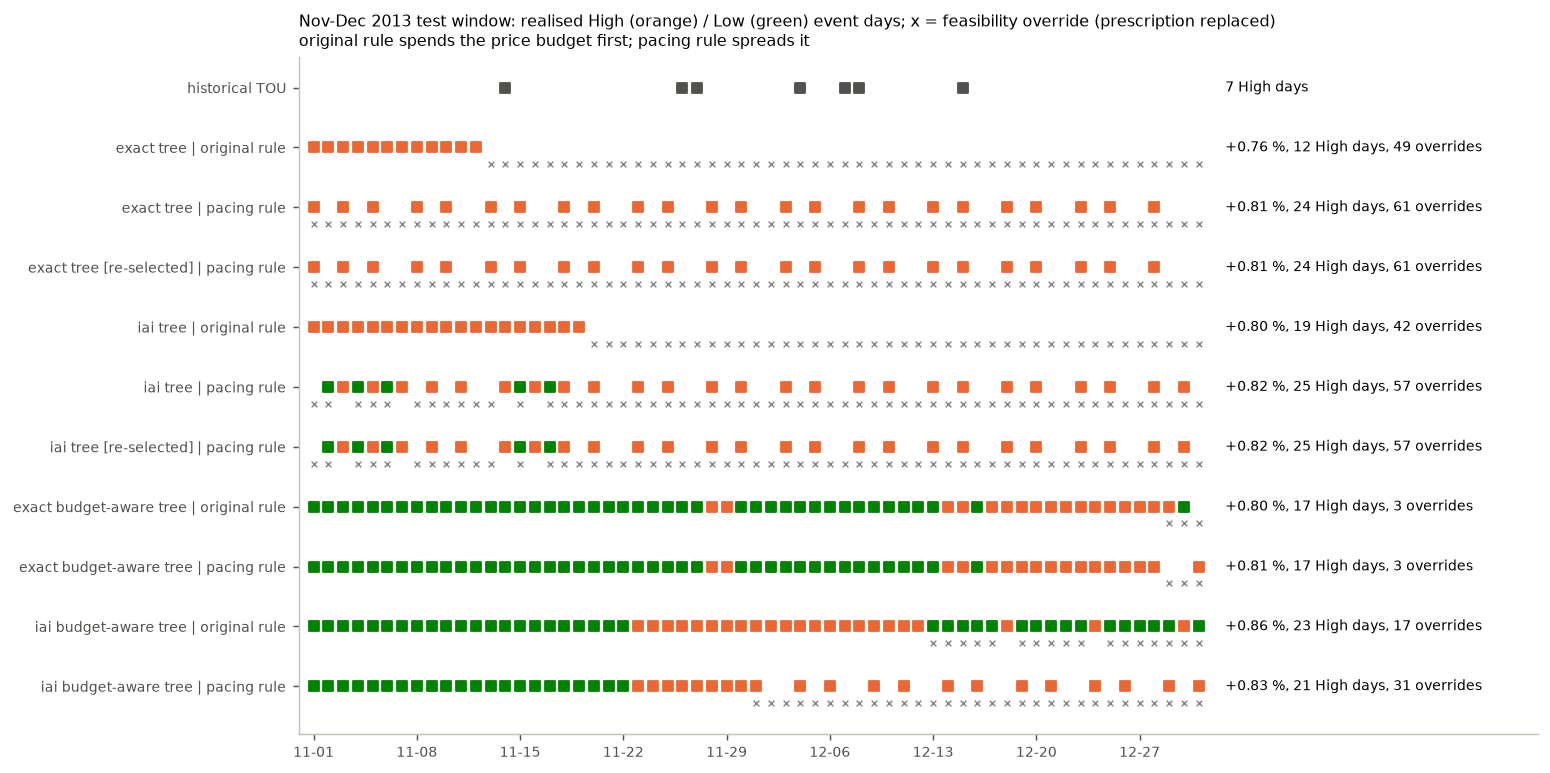

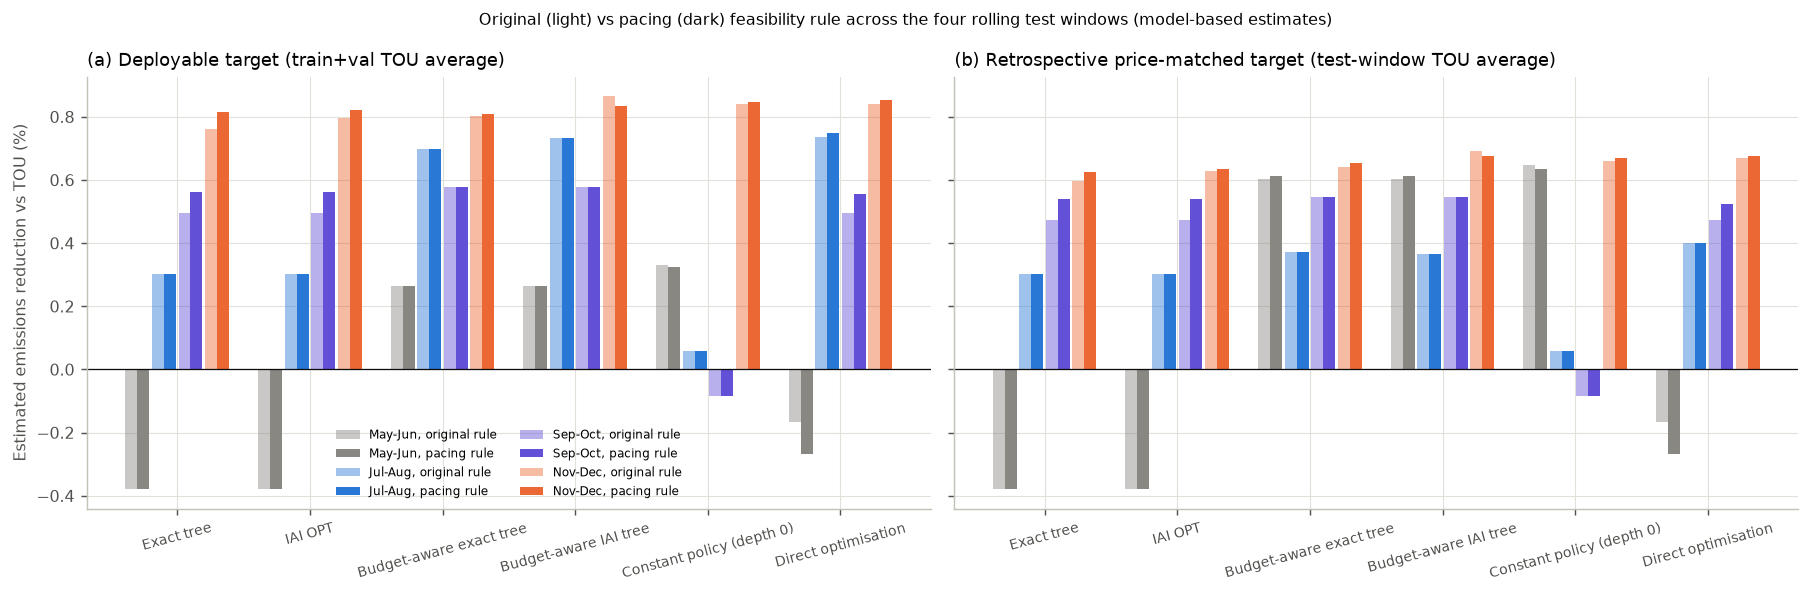

In [30]:
# [SAVED RESULT] all four windows: original vs pacing rule, fixed vs budget-aware trees; Figures 5-6
display(pd.read_csv(RES / "pacing" / "pacing_summary.csv")[["policy", "rule", "mean_reduction_pct", "min_reduction_pct", "mean_bill_change_pct", "mean_overrides"]])
display(Image(filename=str(RES / "figures" / "fig5_pacing_timeline.png"), width=950))
display(Image(filename=str(RES / "figures" / "fig6_pacing_rolling.png"), width=950))

## 7. Household affordability constraints 🟩

**Bill metric at decision time.** For day *d* and schedule *a*, the predicted price paid (consumption-weighted, p/kWh) from
the decision-time demand forecast $\hat y$ (no consumption of day *d* or later):

$$\hat\pi_{d,a} = \frac{\sum_t p_t(a)\,\hat y_{d,t}(a)}{\sum_t \hat y_{d,t}(a)}\qquad(\hat\pi = 11.76 \text{ for the all-Normal day})$$

Simulated kWh changes are < 1 %, so the change in price paid ≈ the change in household bill.

**Cap** (pre-established reference): $\frac1D\sum_d \hat\pi_{d,a_d} \le (1+x)\,\pi_{ref}$, $x\in\{0,5,10\}\%$, where
$\pi_{ref}$ is the historical TOU price paid over **train + validation** (known before the test window).

**Two ways to impose it.**
1. *Rule only:* `multi_budget_rule` enforces both budgets (announced price ≤ T and predicted price paid ≤ cap) online;
   the all-Normal day satisfies both, so it never fails.
2. *Penalty + rule:* retrain the budget-aware tree on $E + \mu\,\pi + \lambda(s)\,p$ (μ from a 9-value grid and depth
   chosen on validation under the capped rule), then apply the same rule.

**Primary candidate:** budget-aware IAI tree, +5 % cap, penalty + rule.

In [31]:
# [SOURCE] the multi-budget rule and the experiment's training / selection / rollout functions
show(PO.multi_budget_rule); show(M11.Fold); show(M11.ba_set); show(M11.select); show(M11.rollout)

**Source:** `carbon_tariff_pipeline/lib/policy.py` line 205

def multi_budget_rule(rankings, budgets):
    """Feasibility rule with SEVERAL period-average budgets (added 2026-11-14 for the bill-constraint experiment;
    feasibility_rule is unchanged). budgets = [(values (D, A), target), ...]: values[k, a] is the per-day quantity
    of action a on day k that budget j averages over the period (e.g. time-average announced price; predicted
    consumption-weighted price paid), all known at day k's announcement. Day k takes the first action in its ranking
    such that, for every budget j, S_j + v_j[k, a] + (D-k-1) * v_j[k, Normal] <= D * T_j (the target stays attainable
    if all remaining days were all-Normal, as in feasibility_rule). Requires v_j[:, Normal] <= T_j, so the all-Normal
    day is always admissible and the rule never fails. Callable rankings receive budget 0's slack (as in
    feasibility_rule). With a single budget it equals feasibility_rule. Returns (actions, n_adjustments,
    blocked_by) where blocked_by[j] counts the overridden days on which budget j ruled out the first-ranked action."""
    Vs = [np.asarray(v, float) for v, _ in budgets]
    Ts = [float(t) for _, t in budgets]
    D = len(Vs[0])
    for V, T in zip(Vs, Ts):
        assert (V[:, NORMAL] <= T + 1e-9).all(), "an all-Normal day must always fit every budget"
    S = [0.0] * len(Vs)
    out, adj, blocked = [], 0, [0] * len(Vs)
    ok = lambda j, k, a: S[j] + Vs[j][k, a] + (D - k - 1) * Vs[j][k, NORMAL] <= D * Ts[j] + 1e-9
    for k in range(D):
        rank = rankings(k, budget_slack(S[0], k, D, Ts[0], Vs[0][k, NORMAL])) if callable(rankings) else rankings[k]
        for i, a in enumerate(rank):
            if all(ok(j, k, a) for j in range(len(Vs))):
                if i > 0:
                    adj += 1
                    for j in range(len(Vs)):
                        blocked[j] += not ok(j, k, rank[0])
                out.append(a)
                for j in range(len(Vs)):
                    S[j] += Vs[j][k, a]
                break
    return np.array(out), adj, blocked

**Source:** `carbon_tariff_pipeline/scripts/11_bill_constraint.py` line 80

class Fold(M10.FoldData):
    def __init__(self, mm):
        super().__init__(mm)
        K = S3.costs(self.world, self.world.m_menu(self.menu), self.menu)
        assert np.allclose(K["E"], self.E)
        self.Pi_fit, self.Pi_dec = K["paid"], K["paid_f"]       # realised (past days: fitting) / decision-time forecast
        f = self.fold
        daily_paid = np.array([price_paid(S3.PRICE_H[d], S3.YALL[d]) for d in range(365)])
        self.pi_ref = float(daily_paid[f.trainval].mean())     # deployable reference (train + val, observed)
        self.pi_ref_test = float(daily_paid[f.test].mean())    # retrospective reference (test window)
        assert np.allclose(self.Pi_dec[:, NORMAL], PRICE["N"]) and np.allclose(self.Pi_fit[:, NORMAL], PRICE["N"])

**Source:** `carbon_tariff_pipeline/scripts/11_bill_constraint.py` line 93

def ba_set(fd, days, mu):
    """Budget-aware training set with bill penalty: E' = E + mu * pi (realised, past days); lambda per budget level."""
    return S3.paced_training_set(fd.E + mu * fd.Pi_fit, fd.P, days)

**Source:** `carbon_tariff_pipeline/scripts/11_bill_constraint.py` line 161

def select(fd, solver, cap, mus):
    """(mi, depth) on validation under the capped rule: min validation emissions; ties -> shallower, fewer overrides, smaller mu."""
    va = fd.fold.val
    grid = []
    for mi in mus:
        for d in DEPTHS:
            _, one = tree(fd, solver, mi, d, "tr")
            acts, adj, _, _ = rollout(fd, one, va, fd.target, cap)
            grid.append({"mi": mi, "mu": MU_GRID[mi], "depth": d, "val_emissions_kg": float(fd.E[va, acts].sum()), "adjustments": adj,
                         "val_pred_paid": float(fd.Pi_dec[va, acts].mean())})
    return pick_near_best(grid, lambda g: (g["depth"], g["adjustments"], g["mu"])), grid

**Source:** `carbon_tariff_pipeline/scripts/11_bill_constraint.py` line 148

def rollout(fd, one, days, T, cap):
    """Run the rule on `days`; cap None = original rule (announced-price budget only)."""
    budgets = [(fd.P[days], T)] + ([] if cap is None else [(fd.Pi_dec[days], cap)])
    first = []

    def rk(k, sl):
        r = ranks(one, days)(k, sl)
        first.append(int(r[0]))
        return r
    acts, adj, blocked = multi_budget_rule(rk, budgets)
    return acts, adj, blocked, np.array(first)

In [32]:
# [TRAIN — full mode only] IAI bill-penalised budget-aware fits for Nov-Dec (temp folder), then mu/depth selection on validation
aff = load_json(RES / "affordability" / "affordability_results.json")["folds"]["11"]
cap5 = 1.05 * fd.pi_ref
print(f"reference price paid (train+val historical TOU) = {fd.pi_ref:.3f} p/kWh -> +5 % cap = {cap5:.3f}; "
      f"historical TOU price paid in the test window = {fd.pi_ref_test:.3f} (retrospective, not used)")
tmp_bill = None
if FULL and JULIA:
    tmp_bill = tempfile.TemporaryDirectory(prefix="iai_bill_"); M11.BILL_DIR = Path(tmp_bill.name); M11._TREES.clear()
    M11.export_iai([fd])                                          # 54 IAI fits: 9 mu x 3 depths x (train, train+val)
    print("IAI fits written to a temporary folder")
elif not (M11.BILL_DIR / "cases.csv").exists():
    print("saved IAI bill-penalised fits not present (gitignored); run the affordability stage — evaluation below is skipped")
else:
    print("[REVIEW] no tree fitted; reading the SAVED IAI fits from", M11.BILL_DIR.relative_to(ROOT), "(validation replay only)")

reference price paid (train+val historical TOU) = 13.748 p/kWh -> +5 % cap = 14.436; historical TOU price paid in the test window = 13.002 (retrospective, not used)
[REVIEW] no tree fitted; reading the SAVED IAI fits from results/mvp/outputs/iai_bill_average_mvp (validation replay only)


In [33]:
# [EVALUATE] primary candidate and the rule-only variant on the Nov-Dec test window
rows_ = []
for variant, mus in ([] if not (M11.BILL_DIR / "cases.csv").exists() else (("rule only", [0]), ("penalty + rule", list(range(len(M11.MU_GRID)))))):
    pick, _ = M11.select(fd, "iai", cap5, mus)
    root, one = M11.tree(fd, "iai", pick["mi"], pick["depth"], "tv")
    acts, adj, blocked, first = M11.rollout(fd, one, te, fd.target, cap5)
    e = M11.evaluate(fd, acts, adj, blocked, first, cap5, 0.05, root)
    rows_.append({"variant": variant, "mu": pick["mu"], "depth": pick["depth"], "reduction (%)": e["emissions_reduction_pct"],
                  "avg announced price": e["mean_price"], "predicted price paid": e["pred_daily_paid_mean"], "simulated price paid": e["sim_daily_paid_mean"],
                  "cap": cap5, "bill change vs historical TOU (%)": e["bill_change_mean_pct"], "overrides (bill-blocked)": f"{e['overrides']} ({e['overrides_blocked_by_bill']})"})
    check(f"IAI +5 % {variant}: test reduction", e["emissions_reduction_pct"], aff["policies"][f"iai|{variant}|5%"]["main"]["emissions_reduction_pct"])
    if variant == "penalty + rule":
        print("Primary candidate tree (Nov-Dec):\n" + e["tree_text"])
display(pd.DataFrame(rows_) if rows_ else Markdown("*skipped: no IAI fits available*"))
if tmp_bill is not None:
    tmp_bill.cleanup(); M11.BILL_DIR = MVP / "iai_bill_average_mvp"

[MATCH] IAI +5 % rule only: test reduction: got 0.769268 | saved 0.769268
[MATCH] IAI +5 % penalty + rule: test reduction: got 0.783293 | saved 0.783293
Primary candidate tree (Nov-Dec):
if remaining budget per remaining day (p/kWh above Normal) < 4:
    -> Normal all day  (n=2128)
else:
    -> High 16:00-20:00  (n=608)



,variant,mu,depth,reduction (%),avg announced price,predicted price paid,simulated price paid,cap,bill change vs historical TOU (%),overrides (bill-blocked)
0,rule only,0.000,2,0.769,13.220,14.378,14.368,14.436,9.831,22 (22)
1,penalty + rule,0.004,1,0.783,13.578,14.366,14.328,14.436,9.638,0 (0)


**Is the cap satisfied?** By construction the *predicted* price paid is always within the cap; the *simulated* price paid is
within it in every window for the primary policy. But the bill **relative to the historical TOU of the same test window** is
not guaranteed: that benchmark's own price paid swings between windows (15.5, 12.2, 13.3, 13.0 p/kWh), so a cap stated
against a pre-set reference can be well above it (Jul–Aug: +20 %). A deployable cap must be defined against a reference
fixed in advance.

,x_pct,variant,mean_reduction_pct,mean_bill_change_pct,mean_bill_change_gbp,windows_sim_within_cap,windows_bill_within_x,mean_overrides
0,none,unconstrained,0.610,10.762,7.188,-,-,5.00
1,0,rule only,0.462,3.696,2.036,3/4,1/4,12.75
2,0,penalty + rule,0.438,0.384,-0.460,3/4,1/4,5.75
3,5,rule only,0.568,8.613,5.518,3/4,1/4,8.00
4,5,penalty + rule,0.585,7.344,4.697,4/4,1/4,0.50
5,10,rule only,0.610,10.762,7.188,4/4,1/4,5.00
6,10,penalty + rule,0.614,8.919,5.989,4/4,2/4,5.00


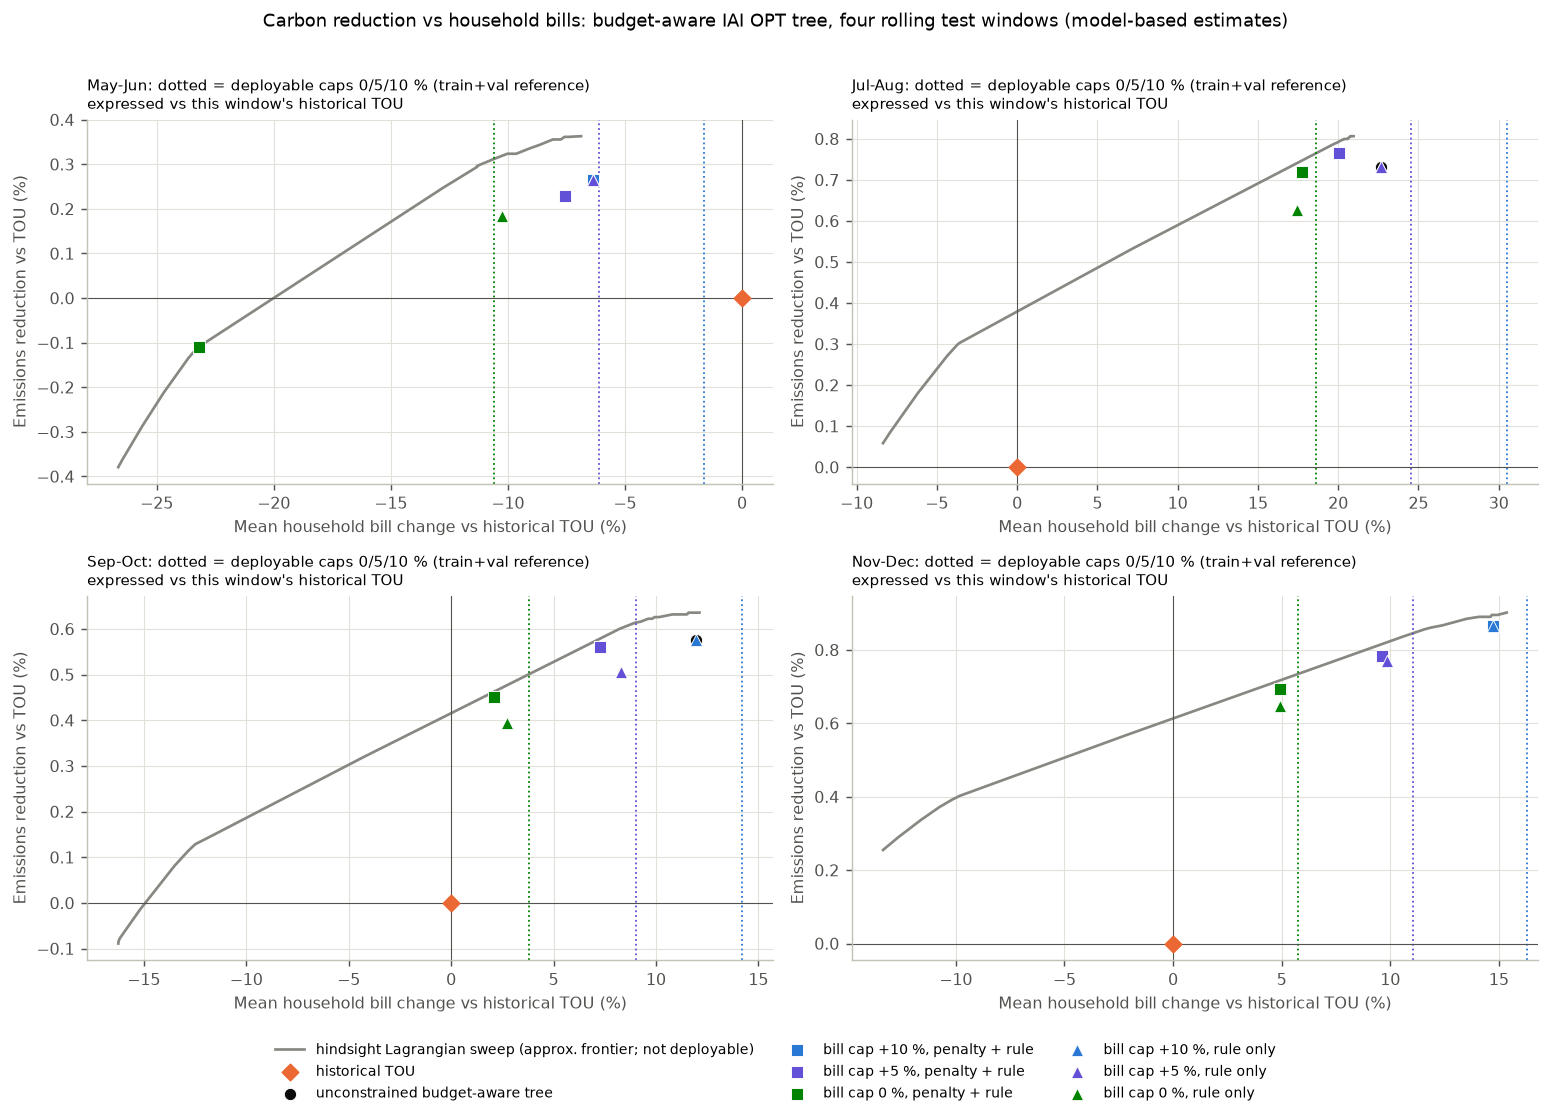

In [34]:
# [SAVED RESULT] the 0 / 5 / 10 % cap experiments across the four windows; Figure 7
af = pd.read_csv(RES / "affordability" / "affordability_summary.csv")
display(af[af.solver == "iai"][["x_pct", "variant", "mean_reduction_pct", "mean_bill_change_pct", "mean_bill_change_gbp", "windows_sim_within_cap", "windows_bill_within_x", "mean_overrides"]])
display(Image(filename=str(RES / "figures" / "fig7_carbon_vs_bills.png"), width=950))

## 8. Final evaluation 🟩

All major policies across the four rolling test windows, each with its own deployable price target (assembled by
`12_final_summary.py` from the saved outputs).

**Emissions reduction vs historical TOU (%)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.000,0.000,0.000,0.000,0.000
Carbon heuristic,-0.578,0.323,-0.294,-0.290,-0.210
"Policy tree, exact solver (Clement)",-0.379,0.302,0.495,0.763,0.295
IAI OPT,-0.379,0.302,0.495,0.796,0.303
Direct optimisation,-0.167,0.736,0.495,0.841,0.477
Budget-aware IAI OPT (no bill cap),0.264,0.732,0.577,0.865,0.610
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",0.228,0.767,0.561,0.783,0.585
Oracle (hindsight; reference only),0.363,0.805,0.621,0.890,0.670


**Mean household bill change vs historical TOU (%)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.000,0.000,0.000,0.000,0.000
Carbon heuristic,-7.333,19.734,5.292,4.680,5.593
"Policy tree, exact solver (Clement)",-26.642,-3.607,4.863,8.212,-4.293
IAI OPT,-26.642,-3.607,4.863,9.513,-3.968
Direct optimisation,-23.746,19.250,4.863,14.024,3.598
Budget-aware IAI OPT (no bill cap),-6.361,22.698,11.978,14.732,10.762
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",-7.566,20.028,7.275,9.638,7.344
Oracle (hindsight; reference only),-6.874,20.962,11.881,14.899,10.217


**Average announced price (p/kWh)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,15.002,12.278,13.520,12.795,13.399
Carbon heuristic,13.606,14.092,13.606,13.606,13.728
"Policy tree, exact solver (Clement)",10.789,11.760,13.578,13.578,12.426
IAI OPT,10.789,11.760,13.578,13.578,12.426
Direct optimisation,11.517,14.054,13.578,13.594,13.186
Budget-aware IAI OPT (no bill cap),13.554,14.065,13.601,13.579,13.700
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",13.582,14.070,13.578,13.578,13.702
Oracle (hindsight; reference only),13.618,14.082,13.560,13.551,13.703


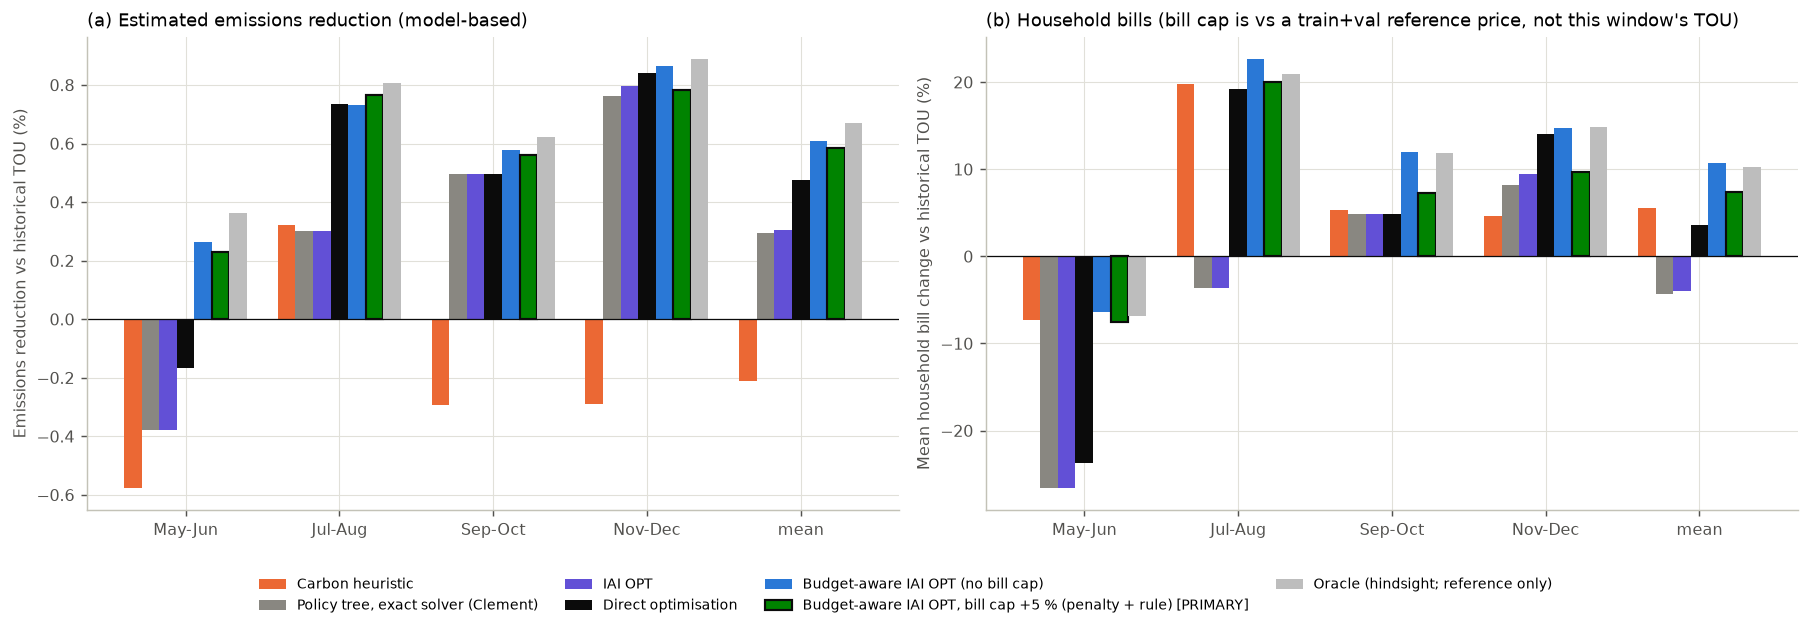

In [35]:
# [SAVED RESULT] final comparison
fc = pd.read_csv(RES / "tables" / "final_comparison.csv")
order = list(dict.fromkeys(fc.policy))
for col, title in (("reduction_pct", "Emissions reduction vs historical TOU (%)"), ("bill_change_pct", "Mean household bill change vs historical TOU (%)"),
                   ("avg_announced_price", "Average announced price (p/kWh)")):
    t = fc.pivot_table(index="policy", columns="window", values=col, sort=False).reindex(order)[["May-Jun", "Jul-Aug", "Sep-Oct", "Nov-Dec"]]
    t["mean"] = t.mean(axis=1); display(Markdown(f"**{title}**")); display(t)
display(Image(filename=str(RES / "figures" / "fig8_final_comparison.png"), width=950))

**Findings (model-based).**
1. Demand-aware policies reduce estimated household emissions at a comparable average announced price, but the effect is
   small (≈ 0.2–0.8 % over two months); the carbon-only heuristic *increases* emissions because Low prices raise demand.
2. IAI and the exact solver give practically identical trees; the feasibility rule, not the tree, drives fixed policies.
3. Remaining budget as a **state feature** (budget-aware trees) is what makes the policy robust in all four windows.
4. A +5 % bill cap (penalty + rule) keeps ≈ 96 % of the reduction and lowers the mean bill increase from +10.8 % to +7.3 %.
   The primary tree is mostly a one-split rule on the remaining budget — readable, but it does not use the carbon forecast
   to time events; its benefit comes from evening conservation.

**Limitations.** Observational demand response (no fatigue / income effects; cluster 3 dominates); bootstrap only for
Nov–Dec; hyper-parameters chosen on single 2-month windows; one year, one city.

## 9. Notebook self-checks

In [36]:
# [CHECK] (1) the code shown is the committed project source; (2) review mode wrote nothing
r = subprocess.run(["git", "diff", "--quiet", "HEAD", "--", "carbon_tariff_pipeline", "CVAE_reproduction/lib", "CVAE_reproduction/scripts", "run_mvp.py"], cwd=ROOT)
print("displayed source == committed source (no uncommitted edits to the project code):", r.returncode == 0)
after = tree_hashes()
changed = sorted(f for f in set(HASH0) | set(after) if HASH0.get(f) != after.get(f))
if FULL:
    print(f"full mode: {len(changed)} saved files differ from before the run (expected 0 for a deterministic re-run): {changed[:10]}")
else:
    print(f"review mode: {len(after)} files re-hashed; changed: {changed}")
    assert not changed, "review mode must not modify saved results"
print(f"notebook finished in {time.time() - T0:.0f} s (mode {MODE!r})")

displayed source == committed source (no uncommitted edits to the project code): True


review mode: 2103 files re-hashed; changed: []
notebook finished in 2 s (mode 'review')
